# w2 — Từng bước thực hiện W2: Feature draft, test plan và EDA report v1

**Owner:** Thái — Data & ML Evaluation · **Dataset:** PaySim · **Task:** 5.4 / W2 (`Ke_hoach_chi_tiet_project_Fraud_Detection.docx`, mục 5.4)

Notebook mô tả **từng bước** của task W2 và chạy lại toàn bộ trên dữ liệu thật. Mọi con số trong `docs/feature-list.md`, `docs/feature-test-plan.md` và `reports/eda-report-v1.md` lấy từ đây (qua `reports/feature_analysis_summary.json`).

| Bước | Việc theo kế hoạch W2 | Trong notebook |
|---|---|---|
| 0 | (chuẩn bị) nạp dữ liệu, kiểm tra nguồn, tái lập số liệu W1 | Bước 0 |
| 1 | Chia feature thành transaction, account, historical và time features | Bước 1 (1.1 → 1.5) |
| 2 | Với từng feature ghi nguồn, cách tính, thời điểm có thể biết, null policy và leakage risk | Bước 2 |
| 3 | Đề xuất split train/validation/test; cân nhắc split theo thời gian | Bước 3 |
| 4 | Tạo test cases cho boundary values, unknown category, missing fields và threshold | Bước 4 |
| 5 | Review feature list với Đạt và streaming contract với Công Anh | Bước 5 (câu hỏi review; buổi review cần người thực hiện) |

**Đầu ra:** `docs/feature-list.md`, `docs/feature-test-plan.md`, `reports/eda-report-v1.md`, `reports/feature_analysis_summary.json`, hình `reports/figures/fig6…fig10`, đặc tả chạy được `src/evaluation/feature_reference.py`, bộ test `tests/`.

> **Cách chạy:** `jupyter nbconvert --to notebook --execute --inplace w2_feature_draft_test_plan.ipynb` trong thư mục `notebooks/` (hoặc *Run All* trong VS Code với kernel `.venv`). Cần ≈ 3 GB RAM và khoảng 3–5 phút. File dữ liệu được tìm theo thứ tự: biến môi trường `PAYSIM_CSV` → `data/raw/PS_20174392719_1491204439457_log.csv` → `data/paysim dataset.csv`.

In [1]:
import os, sys, json, hashlib, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

ROOT = Path("..").resolve()                          # notebook chạy từ thư mục notebooks/
sys.path.insert(0, str(ROOT))
from src.evaluation import feature_reference as fr   # đặc tả chạy được của docs/feature-list.md

_env = os.environ.get("PAYSIM_CSV")
CANDIDATES = ([Path(_env)] if _env else []) + [ROOT / "data" / "raw" / "PS_20174392719_1491204439457_log.csv",
                                               ROOT / "data" / "paysim dataset.csv"]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Không thấy file PaySim: đặt vào data/raw/ hoặc đặt biến môi trường PAYSIM_CSV.")
FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH = ROOT / "reports" / "feature_analysis_summary.json"
W1 = json.loads((ROOT / "reports" / "eda_summary.json").read_text(encoding="utf-8"))   # số liệu W1 để đối chiếu
T1, T2 = W1["time"]["step_at_70pct_rows"], W1["time"]["step_at_85pct_rows"]            # ranh giới split theo thời gian (W1)
SEED = 42
summary = {"notebook": "w2_feature_draft_test_plan", "spec_version": fr.SPEC_VERSION}

# Style biểu đồ như W1: hợp lệ = xanh, gian lận = cam; thêm tím cho "artifact/ablation", xám cho "loại"
LEGIT, FRAUD, ARTIFACT, MUTED = "#2a78d6", "#eb6834", "#7d5bbe", "#9a9994"
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
STATUS_COLOR = {"Dùng": LEGIT, "Dùng + ablation": ARTIFACT, "Cần xác minh": "#c9a227", "Loại": MUTED}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 9.5, "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110,
})
pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 150)


def compact(x, _=None):
    for div, suf in [(1e9, "B"), (1e6, "M"), (1e3, "K")]:
        if abs(x) >= div:
            return f"{x/div:.1f}".rstrip("0").rstrip(".") + suf
    return f"{x:,.0f}"


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=160, bbox_inches="tight")


def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o


# Định dạng số kiểu Việt Nam trong các đoạn kết luận: 1.234.567 và 12,3%
def vint(x): return f"{int(x):,}".replace(",", ".")
def vpct(x, d=1): return f"{100 * x:.{d}f}%".replace(".", ",")
def vnum(x, d=2): return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")
def vf(x, d=3): return f"{x:.{d}f}".replace(".", ",")
def say(*lines): display(Markdown("\n".join(lines)))


print("Dữ liệu:", DATA_PATH.relative_to(ROOT) if ROOT in DATA_PATH.parents else DATA_PATH.name)

Dữ liệu: data\paysim dataset.csv


## Bước 0 — Chuẩn bị: nạp dữ liệu, kiểm tra nguồn, tái lập số liệu W1

Việc làm:
1. Tính SHA-256 của file và đối chiếu với file đã phân tích ở W1 (`reports/eda_summary.json`). Nếu khớp thì mọi số liệu W1 áp dụng nguyên vẹn cho file này.
2. Mã hóa `nameOrig`/`nameDest` thành số nguyên **trong cùng một không gian mã** (một tài khoản có thể xuất hiện ở cả hai vai trò) để tính feature lịch sử nhanh trên 6,36 triệu dòng.
3. **Không đọc** `newbalanceOrig`, `newbalanceDest`, `isFlaggedFraud`: đây là các cột bị cấm trong feature (`docs/feature-inventory.md`), W2 không cần chúng.
4. Dựng cột phụ `is_tc` (TRANSFER hoặc CASH_OUT), `hour`, `day`, `split` (ranh giới step 323/378 của W1).

In [2]:
size = DATA_PATH.stat().st_size
h = hashlib.sha256()
with open(DATA_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 22), b""):
        h.update(chunk)
sha = h.hexdigest()

NUM = {"step": "int32", "type": "category", "amount": "float64", "oldbalanceOrg": "float64",
       "oldbalanceDest": "float64", "isFraud": "int8"}
df = pd.read_csv(DATA_PATH, usecols=list(NUM), dtype=NUM)
n = len(df)
names = pd.read_csv(DATA_PATH, usecols=["nameOrig", "nameDest"], dtype="string")
codes, uniques = pd.factorize(pd.concat([names["nameOrig"], names["nameDest"]], ignore_index=True))
df["orig_code"] = codes[:n].astype("int32")
df["dest_code"] = codes[n:].astype("int32")
df["dest_is_merchant"] = names["nameDest"].str.startswith("M").to_numpy(dtype=bool)
n_accounts = len(uniques)
del names, codes, uniques

df["row_id"] = np.arange(n, dtype="int32")                                    # transaction_id đề xuất = "txn_" + row_id (7 chữ số)
df["is_tc"] = df["type"].isin(["TRANSFER", "CASH_OUT"]).to_numpy()
df["hour"] = ((df["step"] - 1) % 24).astype("int8")                           # giả định step 1 = 00:00 ngày 1
df["day"] = ((df["step"] - 1) // 24 + 1).astype("int8")
df["split"] = np.select([df["step"] <= T1, df["step"] <= T2], [0, 1], 2).astype("int8")   # 0 train, 1 val, 2 test
SPLITS = ["train", "val", "test"]

src = {"file": DATA_PATH.name, "bytes": size, "sha256": sha, "rows": n, "distinct_accounts": n_accounts}
summary["source"] = src
same_file = size == W1["source"]["bytes"] and sha == W1["source"]["sha256"] and n == W1["source"]["rows"]
print(json.dumps(src, indent=2))
print("Khớp file đã phân tích ở W1 (byte, SHA-256, số dòng):", same_file)
assert same_file, "File khác bản W1: số liệu W1 không còn áp dụng nguyên vẹn"

{
  "file": "paysim dataset.csv",
  "bytes": 493534783,
  "sha256": "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b",
  "rows": 6362620,
  "distinct_accounts": 9073900
}
Khớp file đã phân tích ở W1 (byte, SHA-256, số dòng): True


In [3]:
# Tái lập các số liệu chính của W1 trên dữ liệu vừa nạp
by_type = df.groupby("type", observed=True).agg(rows=("isFraud", "size"), fraud=("isFraud", "sum")).rename(index=str).sort_index()
w1_type = pd.DataFrame(W1["by_type"]).set_index("type")[["rows", "fraud"]].sort_index()
sp = df.groupby("split").agg(rows=("isFraud", "size"), fraud=("isFraud", "sum"))
w1_sp = pd.DataFrame(W1["time_split_proposal"])
repro = {
    "tổng số dòng": n == W1["class_balance"]["rows"],
    "tổng số gian lận": int(df["isFraud"].sum()) == W1["class_balance"]["fraud"],
    "số dòng/gian lận theo loại giao dịch": bool((by_type.to_numpy() == w1_type.to_numpy()).all()),
    "số dòng/gian lận theo split 323/378": bool((sp["rows"].to_numpy() == w1_sp["rows"].to_numpy()).all()
                                                 and (sp["fraud"].to_numpy() == w1_sp["fraud"].to_numpy()).all()),
}
summary["w1_reproduction"] = repro
print(pd.Series(repro).to_string())
assert all(repro.values())

tổng số dòng                            True
tổng số gian lận                        True
số dòng/gian lận theo loại giao dịch    True
số dòng/gian lận theo split 323/378     True


## Bước 1 — Chia feature thành 4 nhóm và kiểm chứng trên dữ liệu thật

Kế hoạch yêu cầu chia feature thành *transaction, account, historical, time*. Danh sách ứng viên lấy từ `docs/feature-inventory.md` (W1), cộng các feature lịch sử mà W1 đánh dấu "cần xác minh". Với mỗi nhóm, notebook tính các con số để quyết định **Dùng / Dùng + ablation / Cần xác minh / Loại**.

| Nhóm | Ứng viên | Câu hỏi cần trả lời bằng số liệu |
|---|---|---|
| Transaction | `type`, `log_amount`, `is_tc`, `amount_is_round` | `amount` có giá trị biên nào ảnh hưởng validation? "Tròn số" là hành vi thật hay artifact? |
| Account | `dest_is_merchant`, `oldbalanceOrg`, `oldbalanceDest` và các feature suy ra từ số dư | Có mang thông tin ngoài `type` không? Số dư là tín hiệu hay artifact của simulator? |
| Historical | `dest_txn_count_past_24h`, `dest_amount_sum_past_24h`, `dest_seen_before`, lịch sử theo tài khoản gửi | Có tín hiệu không? Cần bao nhiêu state? Streaming khởi động nguội có lệch so với batch không? |
| Time | `hour_of_day`, `day_index`, `step` thô | Tín hiệu theo giờ là hành vi hay do cách simulator sinh dữ liệu? |

Quy ước: **TC** = TRANSFER + CASH_OUT (toàn bộ gian lận nằm ở đây). Khi so sánh phân phối giữa lớp gian lận và hợp lệ, ô nào ghi "(amount > 0)" thì loại 16 dòng `amount = 0`.

### 1.1 Transaction features: `type`, `amount`

Kiểm tra: giá trị biên của `amount` (để viết validation và test boundary), trần 10.000.000, và liệu "amount tròn nghìn" có phải tín hiệu thật.

In [4]:
tc = df[df["is_tc"]]
tcp = tc[tc["amount"] > 0]                      # (amount > 0)
fraud_mask = tcp["isFraud"].to_numpy() == 1
amt = tcp["amount"].to_numpy()


def contrast(mask):
    """Tỷ lệ gian lận / hợp lệ thỏa điều kiện; mask theo thứ tự các dòng của tcp."""
    mask = np.asarray(mask, dtype=bool)
    return {"fraud_share": float(mask[fraud_mask].mean()), "legit_share": float(mask[~fraud_mask].mean()),
            "rows": int(mask.sum()), "fraud_rate_among_rows": float(fraud_mask[mask].mean()) if mask.any() else None}


fraud_by_type = df.groupby("type", observed=True)["isFraud"].sum().rename(index=str).to_dict()
rate_by_type = df.groupby("type", observed=True)["isFraud"].mean().rename(index=str).to_dict()
tx = {
    "amount_zero_rows": int((df["amount"] == 0).sum()),
    "amount_zero_types": df.loc[df["amount"] == 0, "type"].astype(str).value_counts().to_dict(),
    "amount_min_positive": float(df.loc[df["amount"] > 0, "amount"].min()),
    "amount_max": float(df["amount"].max()),
    "negative_values": int((df[["amount", "oldbalanceOrg", "oldbalanceDest"]] < 0).to_numpy().sum()),
    "non_finite_values": int((~np.isfinite(df[["amount", "oldbalanceOrg", "oldbalanceDest"]].to_numpy())).sum()),
    "round_1000": contrast(amt % 1000 == 0),
    "eq_10M": contrast(amt == 1e7),
    "round_1000_rows_exactly_10M": int(((amt % 1000 == 0) & (amt == 1e7)).sum()),
    "gt_10M_legit_rows": int(((amt > 1e7) & ~fraud_mask).sum()),
    "gt_10M_fraud_rows": int(((amt > 1e7) & fraud_mask).sum()),
    "fraud_by_type": fraud_by_type, "fraud_rate_by_type": rate_by_type,
    "tc_rows": int(len(tc)), "tc_share_rows": float(len(tc) / n),
}
summary["transaction"] = tx

ranges = pd.DataFrame({c: {"min": df[c].min(), "max": df[c].max(), "số dòng = 0": int((df[c] == 0).sum()),
                           "số dòng < 0": int((df[c] < 0).sum())} for c in ["step", "amount", "oldbalanceOrg", "oldbalanceDest"]}).T
summary["ranges"] = ranges.to_dict("index")
ranges_fmt = ranges.copy().astype(object)
for c in ("min", "max"):
    ranges_fmt[c] = [f"{v:,.2f}" for v in ranges[c]]
for c in ("số dòng = 0", "số dòng < 0"):
    ranges_fmt[c] = [f"{int(v):,}" for v in ranges[c]]
display(ranges_fmt)

say("**Kết luận 1.1**",
    f"- `amount`: không âm, không null, không NaN/∞; nhỏ nhất {vnum(tx['amount_min_positive'])} (ngoài {tx['amount_zero_rows']} dòng bằng 0, đều là {', '.join(tx['amount_zero_types'])} gian lận), lớn nhất {vnum(tx['amount_max'])}. "
    "→ validation: từ chối `amount < 0`, NaN, ∞, sai kiểu; **chấp nhận `amount = 0` nhưng gắn cờ** (đây là dòng sau giao dịch bị flag).",
    f"- Gian lận chỉ ở TRANSFER ({vint(fraud_by_type['TRANSFER'])}, tỷ lệ {vpct(rate_by_type['TRANSFER'], 2)}) và CASH_OUT ({vint(fraud_by_type['CASH_OUT'])}, {vpct(rate_by_type['CASH_OUT'], 2)}); CASH_IN, DEBIT, PAYMENT: 0. TC có {vint(tx['tc_rows'])} dòng ({vpct(tx['tc_share_rows'])} dataset).",
    f"- **Trần 10M là artifact:** {vint(tx['gt_10M_legit_rows'])} giao dịch hợp lệ (TC) lớn hơn 10.000.000, **0** giao dịch gian lận. Mô hình cây trên `amount` thô có thể học luật \"> 10M ⇒ hợp lệ\" mà không có ý nghĩa nghiệp vụ.",
    f"- **`amount_is_round` (amount chia hết cho 1.000) → Loại:** {vint(tx['round_1000']['rows'])} dòng TC thỏa điều kiện, trong đó {vint(tx['round_1000_rows_exactly_10M'])} dòng đúng bằng 10.000.000. Tín hiệu ({vpct(tx['round_1000']['fraud_share'])} gian lận so với {vpct(tx['round_1000']['legit_share'], 2)} hợp lệ) chỉ là trần của simulator.")

,min,max,số dòng = 0,số dòng < 0
step,1.00,743.00,0,0
amount,0.00,"92,445,516.64",16,0
oldbalanceOrg,0.00,"59,585,040.37","2,102,449",0
oldbalanceDest,0.00,"356,015,889.35","2,704,388",0


**Kết luận 1.1**
- `amount`: không âm, không null, không NaN/∞; nhỏ nhất 0,01 (ngoài 16 dòng bằng 0, đều là CASH_OUT gian lận), lớn nhất 92.445.516,64. → validation: từ chối `amount < 0`, NaN, ∞, sai kiểu; **chấp nhận `amount = 0` nhưng gắn cờ** (đây là dòng sau giao dịch bị flag).
- Gian lận chỉ ở TRANSFER (4.097, tỷ lệ 0,77%) và CASH_OUT (4.116, 0,18%); CASH_IN, DEBIT, PAYMENT: 0. TC có 2.770.409 dòng (43,5% dataset).
- **Trần 10M là artifact:** 2.443 giao dịch hợp lệ (TC) lớn hơn 10.000.000, **0** giao dịch gian lận. Mô hình cây trên `amount` thô có thể học luật "> 10M ⇒ hợp lệ" mà không có ý nghĩa nghiệp vụ.
- **`amount_is_round` (amount chia hết cho 1.000) → Loại:** 3.271 dòng TC thỏa điều kiện, trong đó 3.207 dòng đúng bằng 10.000.000. Tín hiệu (3,5% gian lận so với 0,11% hợp lệ) chỉ là trần của simulator.

### 1.2 Account features

Kiểm tra `dest_is_merchant` (tài khoản nhận bắt đầu bằng `M`), vai trò chéo giữa tài khoản gửi/nhận và mức lặp của tài khoản gửi. Số dư (`oldbalance*`) được phân tích riêng ở 1.5 vì chúng cần trường bổ sung trong event.

In [5]:
y = df["isFraud"].to_numpy()
m_tc = df["is_tc"].to_numpy()
step = df["step"].to_numpy()
orig, dest = df["orig_code"].to_numpy(), df["dest_code"].to_numpy()

merch = df[df["dest_is_merchant"]]
orig_n = np.bincount(orig, minlength=n_accounts)
first_as_orig = np.full(n_accounts, 10**6, dtype=np.int32); np.minimum.at(first_as_orig, orig, step)
first_as_dest = np.full(n_accounts, 10**6, dtype=np.int32); np.minimum.at(first_as_dest, dest, step)
dest_sent_before = first_as_orig[dest] < step          # tài khoản nhận từng là tài khoản gửi ở step trước
orig_received_before = first_as_dest[orig] < step      # tài khoản gửi từng là tài khoản nhận ở step trước


def class_share(flag, mask=m_tc):
    return {"fraud": float(flag[mask & (y == 1)].mean()), "legit": float(flag[mask & (y == 0)].mean())}


acct = {
    "merchant_rows": int(len(merch)),
    "merchant_types": merch["type"].astype(str).value_counts().to_dict(),
    "merchant_rows_in_TC": int(merch["is_tc"].sum()),
    "orig_distinct": int((orig_n > 0).sum()),
    "orig_repeated_accounts": int((orig_n > 1).sum()),
    "orig_repeated_row_share": float((orig_n[orig] > 1).mean()),
    "orig_repeated_share_TC": class_share(orig_n[orig] > 1),
    "dest_has_sent_before_TC": class_share(dest_sent_before),
    "orig_has_received_before_TC": class_share(orig_received_before),
}
summary["account"] = acct
display(pd.Series({k: (f"{v:,}" if isinstance(v, int) else f"{v:.6f}") for k, v in acct.items() if not isinstance(v, dict)}, name="giá trị").to_frame())
display(pd.DataFrame({k: v for k, v in acct.items() if k.endswith("_TC") and isinstance(v, dict)}).T.rename(columns={"fraud": "gian lận", "legit": "hợp lệ"}))

say("**Kết luận 1.2**",
    f"- **`dest_is_merchant` → Loại.** {vint(acct['merchant_rows'])} dòng có tài khoản nhận là merchant, đều là {', '.join(acct['merchant_types'])}; trong TC có **{acct['merchant_rows_in_TC']}** dòng. Feature này đồng nhất với `type = PAYMENT`, không thêm thông tin nào ngoài `type` (W1 đề xuất đưa vào set A; W2 bỏ).",
    f"- **Lịch sử theo tài khoản gửi → Loại.** Chỉ {vint(acct['orig_repeated_accounts'])} tài khoản gửi xuất hiện hơn một lần ({vpct(acct['orig_repeated_row_share'], 2)} số dòng).",
    f"- **Vai trò chéo → Loại.** Tài khoản nhận từng là tài khoản gửi: {vpct(acct['dest_has_sent_before_TC']['fraud'], 2)} (gian lận) so với {vpct(acct['dest_has_sent_before_TC']['legit'], 2)} (hợp lệ), không có tín hiệu.")

,giá trị
merchant_rows,"2,151,495"
merchant_rows_in_TC,0
orig_distinct,"6,353,307"
orig_repeated_accounts,"9,298"
orig_repeated_row_share,0.002925


,gian lận,hợp lệ
orig_repeated_share_TC,0.00340923,0.00292883
dest_has_sent_before_TC,0.00121758,0.00155565
orig_has_received_before_TC,0,0.000133951


**Kết luận 1.2**
- **`dest_is_merchant` → Loại.** 2.151.495 dòng có tài khoản nhận là merchant, đều là PAYMENT; trong TC có **0** dòng. Feature này đồng nhất với `type = PAYMENT`, không thêm thông tin nào ngoài `type` (W1 đề xuất đưa vào set A; W2 bỏ).
- **Lịch sử theo tài khoản gửi → Loại.** Chỉ 9.298 tài khoản gửi xuất hiện hơn một lần (0,29% số dòng).
- **Vai trò chéo → Loại.** Tài khoản nhận từng là tài khoản gửi: 0,12% (gian lận) so với 0,16% (hợp lệ), không có tín hiệu.

### 1.3 Historical features (theo `destination_account`)

**Định nghĩa dùng xuyên suốt:** với giao dịch ở `step = s` tới tài khoản nhận *d*:
- `dest_txn_count_past_24h` = số giao dịch tới *d* có step trong **[s−24, s−1]**; `dest_amount_sum_past_24h` = tổng `amount` của các giao dịch đó;
- `dest_seen_before` = có ít nhất một giao dịch tới *d* ở step < s (toàn bộ lịch sử).

Giao dịch **cùng step không tính cho nhau**: dữ liệu chỉ có độ phân giải theo giờ nên thứ tự trong cùng step không xác định; định nghĩa này cho cùng kết quả ở batch (cửa sổ theo `step`) và streaming (cửa sổ theo `event_time`) bất kể thứ tự đến. Tính trên **toàn bộ dòng** (mọi loại giao dịch) vì state ở streaming cũng chứa mọi event.

Cài đặt hàng loạt: sắp theo khóa `dest × 1000 + step` rồi dùng `searchsorted` để đếm trong cửa sổ; tổng tiền tính bằng **cent (số nguyên)** để không sai số khi lấy hiệu của tổng tích lũy.

In [6]:
cents = np.rint(df["amount"].to_numpy() * 100).astype(np.int64)
print("Sai lệch lớn nhất giữa amount×100 và số nguyên gần nhất:", float(np.abs(df["amount"].to_numpy() * 100 - cents).max()))
assert np.abs(df["amount"].to_numpy() * 100 - cents).max() < 1e-3          # amount có đúng 2 chữ số thập phân


def window_history(step, dest, cents, window=fr.HISTORY_WINDOW_STEPS):
    """Mỗi dòng: (số giao dịch, tổng cent, đã từng thấy tài khoản nhận) tới cùng tài khoản nhận trong các step [s-window, s-1]."""
    step = step.astype(np.int64); dest = dest.astype(np.int64)
    key = dest * 1000 + step                                                     # step <= 743 < 1000
    order = np.argsort(key, kind="stable")
    ks = key[order]
    prefix = np.concatenate([[0], np.cumsum(cents[order])])
    hi = np.searchsorted(ks, key, side="left")                                   # cùng tài khoản, step < s
    lo = np.searchsorted(ks, dest * 1000 + np.maximum(step - window, 0), side="left")   # cùng tài khoản, step >= s - window
    first = np.searchsorted(ks, dest * 1000, side="left")
    return hi - lo, prefix[hi] - prefix[lo], hi > first


hist_cnt, hist_cents, hist_seen = window_history(step, dest, cents)
hist_sum = hist_cents / 100.0

tcm_y = y[m_tc]
def hist_contrast(flag):
    return {"fraud": float(flag[m_tc][tcm_y == 1].mean()), "legit": float(flag[m_tc][tcm_y == 0].mean())}

hist_stats = {
    "no_txn_24h": hist_contrast(hist_cnt == 0),
    "never_seen": hist_contrast(~hist_seen),
    "count_quantiles_fraud": pd.Series(hist_cnt[m_tc][tcm_y == 1]).quantile([.5, .9, .99]).to_dict(),
    "count_quantiles_legit": pd.Series(hist_cnt[m_tc][tcm_y == 0]).quantile([.5, .9, .99]).to_dict(),
}
summary["historical"] = hist_stats
display(pd.DataFrame({"gian lận": {"không có giao dịch tới tài khoản nhận trong 24 giờ trước": hist_stats["no_txn_24h"]["fraud"],
                                  "chưa từng thấy tài khoản nhận": hist_stats["never_seen"]["fraud"]},
                      "hợp lệ": {"không có giao dịch tới tài khoản nhận trong 24 giờ trước": hist_stats["no_txn_24h"]["legit"],
                                 "chưa từng thấy tài khoản nhận": hist_stats["never_seen"]["legit"]}}))

Sai lệch lớn nhất giữa amount×100 và số nguyên gần nhất: 9.5367431640625e-07


,gian lận,hợp lệ
không có giao dịch tới tài khoản nhận trong 24 giờ trước,0.874467,0.441318
chưa từng thấy tài khoản nhận,0.632656,0.15113


**State cần giữ ở streaming và hiệu ứng khởi động nguội.** Feature lịch sử cần state theo tài khoản nhận. Hai câu hỏi cho Công Anh:
1. Cần giữ bao nhiêu tài khoản trong state? → đếm số tài khoản có ≥ 1 giao dịch trong cửa sổ 24 step ở từng thời điểm (cho `dest_txn_count_past_24h`) và số tài khoản từng xuất hiện (cho `dest_seen_before`, giữ vĩnh viễn).
2. Nếu replay stream bắt đầu đúng tại đầu giai đoạn test (step 379) mà state **rỗng**, giá trị feature lệch bao nhiêu so với batch (batch tính trên toàn bộ lịch sử)?

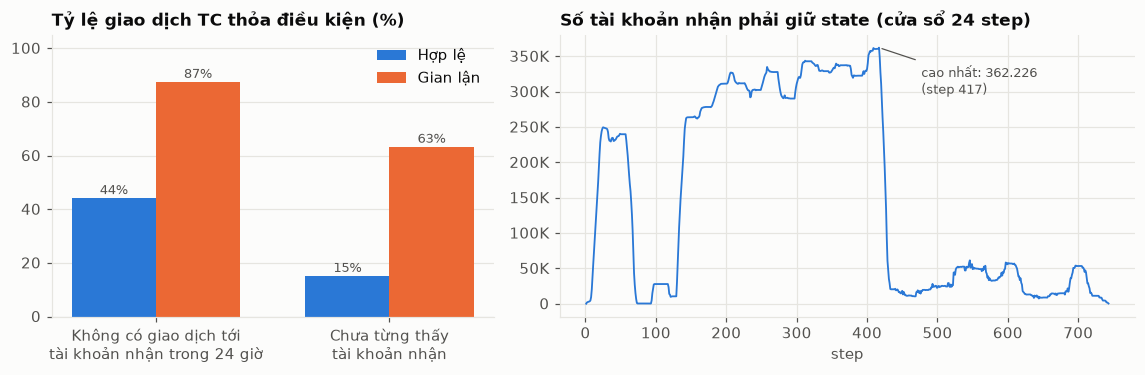

**Kết luận 1.3**
- **Có tín hiệu.** 87,4% giao dịch gian lận tới tài khoản nhận *chưa có giao dịch nào trong 24 giờ trước*, so với 44,1% giao dịch hợp lệ; 36,7% gian lận tới tài khoản "đã từng thấy" so với 84,9% hợp lệ. Định nghĩa chỉ dùng dữ liệu trước thời điểm dự đoán nên không phải leakage, nhưng có thể phản ánh cách simulator chọn tài khoản nhận → **Cần xác minh**, báo cáo ablation A+H ở W3.
- **State:** cửa sổ 24 step cần tối đa 362.226 tài khoản nhận (tại step 417, trung vị 55.730); `dest_seen_before` cần giữ toàn bộ 2.722.362 tài khoản nhận.
- **Khởi động nguội làm lệch feature.** Nếu replay bắt đầu tại step 379 với state rỗng, `dest_txn_count_past_24h` sai ở 38.589/184.520 dòng TC của 24 step đầu (20,9%; 23/298 dòng gian lận). → cần **warm-up 24 step** (replay step 355–378 để nạp state, không chấm điểm).
- `dest_seen_before` sai ở 48,7% dòng TC của cả giai đoạn test nếu state rỗng (17,0% với dòng gian lận): warm-up 24 step **không đủ**, phải nạp state từ batch layer (kiến trúc Lambda) hoặc bỏ feature này khỏi mô hình triển khai.

In [7]:
# (1) Số tài khoản nhận có >= 1 giao dịch trong [s-24, s-1], s = 1..743: hợp các khoảng ảnh hưởng [s_i+1, s_i+24] của từng tài khoản
W = fr.HISTORY_WINDOW_STEPS
order = np.lexsort((step, dest))
d_s, s_s = dest[order], step[order].astype(np.int64)
same = np.r_[False, d_s[1:] == d_s[:-1]]
prev_step = np.r_[0, s_s[:-1]]
start = np.where(same, np.maximum(s_s + 1, prev_step + W + 1), s_s + 1)     # phần cửa sổ chưa được dòng trước của cùng tài khoản phủ
end = s_s + W
keep = start <= end
L = int(step.max()) + W + 3
active = np.cumsum(np.bincount(start[keep], minlength=L) - np.bincount(end[keep] + 1, minlength=L))[1:int(step.max()) + 1]

# (2) Khởi động nguội tại đầu giai đoạn test: state rỗng, chỉ có các event từ step 379
test_first = T2 + 1
m_sub = step >= test_first
cold_cnt, _, cold_seen = window_history(step[m_sub], dest[m_sub], cents[m_sub])
sub_tc, sub_step, sub_y = m_tc[m_sub], step[m_sub], y[m_sub]
first24 = sub_tc & (sub_step < test_first + W)
d_cnt = hist_cnt[m_sub] != cold_cnt
d_seen = hist_seen[m_sub] != cold_seen
state = {
    "active_accounts_max": int(active.max()), "active_accounts_max_step": int(active.argmax() + 1),
    "active_accounts_median": float(np.median(active)), "active_accounts_p95": float(np.percentile(active, 95)),
    "accounts_lifetime": int(len(np.unique(dest))),
    "warmup": {
        "test_first_step": test_first,
        "tc_rows_first_24_steps": int(first24.sum()), "count_differs_first_24_steps": int(d_cnt[first24].sum()),
        "count_differs_share_first_24_steps": float(d_cnt[first24].mean()),
        "count_differs_all_test_tc_rows": int(d_cnt[sub_tc].sum()), "tc_rows_test": int(sub_tc.sum()),
        "fraud_first_24_steps": int((first24 & (sub_y == 1)).sum()), "fraud_count_differs_first_24_steps": int((first24 & d_cnt & (sub_y == 1)).sum()),
        "seen_differs_share_test_tc": float(d_seen[sub_tc].mean()), "seen_differs_fraud_share_test_tc": float(d_seen[sub_tc & (sub_y == 1)].mean()),
    },
}
summary["state"] = state
wu = state["warmup"]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), gridspec_kw={"width_ratios": [1, 1.3]})
labels = ["Không có giao dịch tới\ntài khoản nhận trong 24 giờ", "Chưa từng thấy\ntài khoản nhận"]
x = np.arange(2); w = 0.36
legit_vals = [hist_stats["no_txn_24h"]["legit"] * 100, hist_stats["never_seen"]["legit"] * 100]
fraud_vals = [hist_stats["no_txn_24h"]["fraud"] * 100, hist_stats["never_seen"]["fraud"] * 100]
axes[0].bar(x - w / 2, legit_vals, w, color=LEGIT, label="Hợp lệ")
axes[0].bar(x + w / 2, fraud_vals, w, color=FRAUD, label="Gian lận")
for xi, v in zip(x - w / 2, legit_vals): axes[0].text(xi, v + 1.5, f"{v:.0f}%", ha="center", color=INK2, fontsize=8.5)
for xi, v in zip(x + w / 2, fraud_vals): axes[0].text(xi, v + 1.5, f"{v:.0f}%", ha="center", color=INK2, fontsize=8.5)
axes[0].set_xticks(x); axes[0].set_xticklabels(labels); axes[0].set_ylim(0, 105); axes[0].grid(axis="x", visible=False)
axes[0].set_title("Tỷ lệ giao dịch TC thỏa điều kiện (%)"); axes[0].legend(loc="upper right")
axes[1].plot(np.arange(1, len(active) + 1), active, color=LEGIT, linewidth=1.2)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(compact)); axes[1].set_xlabel("step")
axes[1].set_title("Số tài khoản nhận phải giữ state (cửa sổ 24 step)")
axes[1].annotate(f"cao nhất: {vint(state['active_accounts_max'])}\n(step {state['active_accounts_max_step']})",
                 xy=(state["active_accounts_max_step"], state["active_accounts_max"]),
                 xytext=(state["active_accounts_max_step"] + 60, state["active_accounts_max"] * 0.82),
                 color=INK2, fontsize=8.5, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
fig.tight_layout(); save(fig, "fig6_history_features.png"); plt.show()

say("**Kết luận 1.3**",
    f"- **Có tín hiệu.** {vpct(hist_stats['no_txn_24h']['fraud'])} giao dịch gian lận tới tài khoản nhận *chưa có giao dịch nào trong 24 giờ trước*, so với {vpct(hist_stats['no_txn_24h']['legit'])} giao dịch hợp lệ; {vpct(1 - hist_stats['never_seen']['fraud'])} gian lận tới tài khoản \"đã từng thấy\" so với {vpct(1 - hist_stats['never_seen']['legit'])} hợp lệ. Định nghĩa chỉ dùng dữ liệu trước thời điểm dự đoán nên không phải leakage, nhưng có thể phản ánh cách simulator chọn tài khoản nhận → **Cần xác minh**, báo cáo ablation A+H ở W3.",
    f"- **State:** cửa sổ 24 step cần tối đa {vint(state['active_accounts_max'])} tài khoản nhận (tại step {state['active_accounts_max_step']}, trung vị {vint(state['active_accounts_median'])}); `dest_seen_before` cần giữ toàn bộ {vint(state['accounts_lifetime'])} tài khoản nhận.",
    f"- **Khởi động nguội làm lệch feature.** Nếu replay bắt đầu tại step {wu['test_first_step']} với state rỗng, `dest_txn_count_past_24h` sai ở {vint(wu['count_differs_first_24_steps'])}/{vint(wu['tc_rows_first_24_steps'])} dòng TC của 24 step đầu ({vpct(wu['count_differs_share_first_24_steps'])}; {wu['fraud_count_differs_first_24_steps']}/{wu['fraud_first_24_steps']} dòng gian lận). → cần **warm-up 24 step** (replay step 355–378 để nạp state, không chấm điểm).",
    f"- `dest_seen_before` sai ở {vpct(wu['seen_differs_share_test_tc'])} dòng TC của cả giai đoạn test nếu state rỗng ({vpct(wu['seen_differs_fraud_share_test_tc'])} với dòng gian lận): warm-up 24 step **không đủ**, phải nạp state từ batch layer (kiến trúc Lambda) hoặc bỏ feature này khỏi mô hình triển khai.")

### 1.4 Time features

`hour_of_day = (step − 1) mod 24` (giả định step 1 = 00:00; khi chuyển sang `event_time` cần T0 do Lead chốt, xem `docs/feature-test-plan.md` nhóm EV). Câu hỏi: tỷ lệ gian lận cao vào ban đêm là hành vi hay do cách sinh dữ liệu? Cách kiểm tra: so sánh **số lượng** giao dịch hợp lệ và gian lận theo giờ, không chỉ tỷ lệ.

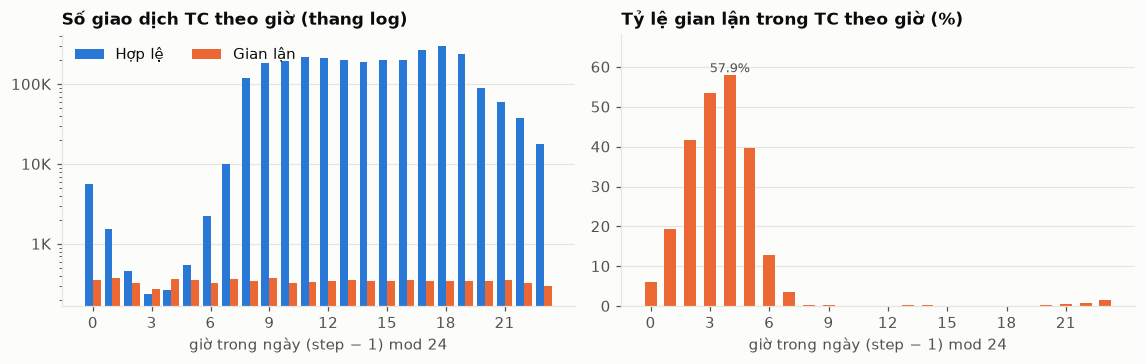

**Kết luận 1.4**
- Số giao dịch gian lận gần như **phẳng theo giờ**: mỗi giờ chiếm 3,3%–4,6% tổng số gian lận (đều đặn ~11 ca mỗi giờ), trong khi giao dịch hợp lệ thay đổi từ 238 (giờ 3) đến 299.591 (giờ 18).
- Tỷ lệ gian lận trong TC đi từ 0,11% (giờ 18) đến 57,9% (giờ 4) **chỉ vì mẫu số (giao dịch hợp lệ) co lại ban đêm**, không phải gian lận tăng. Mô hình học `hour_of_day` sẽ học "giờ vắng giao dịch ⇒ nghi ngờ", một artifact của simulator.
- → `hour_of_day` **Dùng + ablation**: chỉ vào biến thể A+T, luôn báo cáo kèm set A. `day_index` và `step` thô → **Loại** (không tổng quát cho tương lai).

In [8]:
hr = tc.groupby("hour").agg(rows=("isFraud", "size"), fraud=("isFraud", "sum"))
hr["legit"] = hr["rows"] - hr["fraud"]
hr["fraud_rate"] = hr["fraud"] / hr["rows"]
hr["fraud_share_of_all_fraud"] = hr["fraud"] / hr["fraud"].sum()
hour_stats = {
    "fraud_share_per_hour_min": float(hr["fraud_share_of_all_fraud"].min()), "fraud_share_per_hour_max": float(hr["fraud_share_of_all_fraud"].max()),
    "legit_per_hour_min": int(hr["legit"].min()), "legit_per_hour_min_hour": int(hr["legit"].idxmin()),
    "legit_per_hour_max": int(hr["legit"].max()), "legit_per_hour_max_hour": int(hr["legit"].idxmax()),
    "fraud_rate_min": float(hr["fraud_rate"].min()), "fraud_rate_min_hour": int(hr["fraud_rate"].idxmin()),
    "fraud_rate_max": float(hr["fraud_rate"].max()), "fraud_rate_max_hour": int(hr["fraud_rate"].idxmax()),
    "fraud_rate_by_hour": {int(k): float(v) for k, v in hr["fraud_rate"].items()},
}
summary["time_of_day"] = hour_stats

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
xh = hr.index.to_numpy(); w = 0.4
axes[0].bar(xh - w / 2, hr["legit"], w, color=LEGIT, label="Hợp lệ")
axes[0].bar(xh + w / 2, hr["fraud"], w, color=FRAUD, label="Gian lận")
axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(compact))
axes[0].set_title("Số giao dịch TC theo giờ (thang log)"); axes[0].legend(loc="upper left", ncol=2)
axes[1].bar(xh, hr["fraud_rate"] * 100, width=0.6, color=FRAUD)
axes[1].set_title("Tỷ lệ gian lận trong TC theo giờ (%)")
peak = hour_stats["fraud_rate_max_hour"]
axes[1].text(peak, hr.loc[peak, "fraud_rate"] * 100, f"{hr.loc[peak, 'fraud_rate'] * 100:.1f}%", ha="center", va="bottom", color=INK2, fontsize=8.5)
axes[1].set_ylim(0, hr["fraud_rate"].max() * 100 * 1.18)
for ax in axes:
    ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("giờ trong ngày (step − 1) mod 24"); ax.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "fig7_hour_volume.png"); plt.show()

say("**Kết luận 1.4**",
    f"- Số giao dịch gian lận gần như **phẳng theo giờ**: mỗi giờ chiếm {vpct(hour_stats['fraud_share_per_hour_min'])}–{vpct(hour_stats['fraud_share_per_hour_max'])} tổng số gian lận (đều đặn ~11 ca mỗi giờ), trong khi giao dịch hợp lệ thay đổi từ {vint(hour_stats['legit_per_hour_min'])} (giờ {hour_stats['legit_per_hour_min_hour']}) đến {vint(hour_stats['legit_per_hour_max'])} (giờ {hour_stats['legit_per_hour_max_hour']}).",
    f"- Tỷ lệ gian lận trong TC đi từ {vpct(hour_stats['fraud_rate_min'], 2)} (giờ {hour_stats['fraud_rate_min_hour']}) đến {vpct(hour_stats['fraud_rate_max'])} (giờ {hour_stats['fraud_rate_max_hour']}) **chỉ vì mẫu số (giao dịch hợp lệ) co lại ban đêm**, không phải gian lận tăng. Mô hình học `hour_of_day` sẽ học \"giờ vắng giao dịch ⇒ nghi ngờ\", một artifact của simulator.",
    "- → `hour_of_day` **Dùng + ablation**: chỉ vào biến thể A+T, luôn báo cáo kèm set A. `day_index` và `step` thô → **Loại** (không tổng quát cho tương lai).")

### 1.5 Balance features (feature set B)

Các cột số dư *trước* giao dịch (`oldbalanceOrg`, `oldbalanceDest`) và feature suy ra. Số dư *sau* giao dịch đã bị loại ở W1 (post-transaction). Câu hỏi: mức độ artifact, và `drains_origin` cần dung sai bao nhiêu để không phụ thuộc cách lưu số thực.

In [9]:
oo = tcp["oldbalanceOrg"].to_numpy(); od = tcp["oldbalanceDest"].to_numpy()
drain_exact = (amt == oo)
drain_tol = np.abs(amt - oo) < fr.DRAIN_TOLERANCE
bal = {
    "oldbalanceOrg = 0": contrast(oo == 0),
    "amount > oldbalanceOrg (rút quá số dư)": contrast(amt > oo),
    "amount = oldbalanceOrg (so khớp chính xác)": contrast(drain_exact),
    "|amount − oldbalanceOrg| < 0,005 (drains_origin)": contrast(drain_tol),
    "|amount − oldbalanceOrg| ≤ 0,01": contrast(np.abs(amt - oo) <= 0.01),
    "oldbalanceDest = 0 (dest_balance_zero)": contrast(od == 0),
}
ratio = amt / (oo + 1.0)
bal_table = pd.DataFrame(bal).T.rename(columns={"fraud_share": "% gian lận", "legit_share": "% hợp lệ", "rows": "số dòng",
                                                 "fraud_rate_among_rows": "tỷ lệ gian lận trong nhóm"})
bal_table["số dòng"] = bal_table["số dòng"].astype(int)
summary["balance"] = {"contrasts": bal, "ratio_median_fraud": float(np.median(ratio[fraud_mask])), "ratio_median_legit": float(np.median(ratio[~fraud_mask])),
                      "fraud_not_drained_rows": int((fraud_mask & ~drain_tol).sum()),
                      "fraud_not_drained_amount_ge_10M": int((fraud_mask & ~drain_tol & (amt >= 1e7)).sum())}
display(bal_table)

b = summary["balance"]
say("**Kết luận 1.5**",
    f"- `drains_origin` (amount = số dư người gửi trước giao dịch): {vint(bal['amount = oldbalanceOrg (so khớp chính xác)']['rows'])} dòng, **100% là gian lận** ({vpct(bal['amount = oldbalanceOrg (so khớp chính xác)']['fraud_share'])} số ca gian lận, 0% hợp lệ). Dung sai nửa cent cho {vint(bal['|amount − oldbalanceOrg| < 0,005 (drains_origin)']['rows'])} dòng, dung sai 0,01 cho {vint(bal['|amount − oldbalanceOrg| ≤ 0,01']['rows'])} dòng (thêm 1 dòng hợp lệ) → chọn **dung sai < 0,005** để không lẫn giao dịch hợp lệ.",
    f"- `oldbalanceOrg = 0` xảy ra ở {vpct(bal['oldbalanceOrg = 0']['legit_share'])} giao dịch hợp lệ so với {vpct(bal['oldbalanceOrg = 0']['fraud_share'], 2)} gian lận; `amount > oldbalanceOrg` ở {vpct(bal['amount > oldbalanceOrg (rút quá số dư)']['legit_share'])} giao dịch hợp lệ so với {vpct(bal['amount > oldbalanceOrg (rút quá số dư)']['fraud_share'], 2)} gian lận. Giao dịch hợp lệ rút quá số dư là bất thường so với thực tế → **artifact của simulator**, mô hình sẽ học \"số dư ≠ amount ⇒ hợp lệ\".",
    f"- {b['fraud_not_drained_rows']} giao dịch gian lận (amount > 0) **không** phải rút sạch, trong đó {b['fraud_not_drained_amount_ge_10M']} ca có amount ≥ 10.000.000 (bị chặn ở trần trong khi số dư lớn hơn).",
    "- → toàn bộ nhóm số dư là **Dùng + ablation** (feature set B): chỉ được báo cáo kèm kết quả set A không có chúng, và cần trường `*_balance_before` trong event.")

,% gian lận,% hợp lệ,số dòng,tỷ lệ gian lận trong nhóm
oldbalanceOrg = 0,0.0030499,0.473732,1308566,1.91049e-05
amount > oldbalanceOrg (rút quá số dư),0.00353788,0.900952,2488634,1.1653e-05
amount = oldbalanceOrg (so khớp chính xác),0.978163,0,8018,1
"|amount − oldbalanceOrg| < 0,005 (drains_origin)",0.978163,0,8018,1
"|amount − oldbalanceOrg| ≤ 0,01",0.978163,3.62031e-07,8019,0.999875
oldbalanceDest = 0 (dest_balance_zero),0.652068,0.139009,389314,0.0137293


**Kết luận 1.5**
- `drains_origin` (amount = số dư người gửi trước giao dịch): 8.018 dòng, **100% là gian lận** (97,8% số ca gian lận, 0% hợp lệ). Dung sai nửa cent cho 8.018 dòng, dung sai 0,01 cho 8.019 dòng (thêm 1 dòng hợp lệ) → chọn **dung sai < 0,005** để không lẫn giao dịch hợp lệ.
- `oldbalanceOrg = 0` xảy ra ở 47,4% giao dịch hợp lệ so với 0,30% gian lận; `amount > oldbalanceOrg` ở 90,1% giao dịch hợp lệ so với 0,35% gian lận. Giao dịch hợp lệ rút quá số dư là bất thường so với thực tế → **artifact của simulator**, mô hình sẽ học "số dư ≠ amount ⇒ hợp lệ".
- 179 giao dịch gian lận (amount > 0) **không** phải rút sạch, trong đó 145 ca có amount ≥ 10.000.000 (bị chặn ở trần trong khi số dư lớn hơn).
- → toàn bộ nhóm số dư là **Dùng + ablation** (feature set B): chỉ được báo cáo kèm kết quả set A không có chúng, và cần trường `*_balance_before` trong event.

## Bước 2 — Định nghĩa từng feature: nguồn, cách tính, thời điểm biết, null policy, leakage risk

Ba việc:
1. **Sức mạnh tín hiệu đơn biến (2.1).** Xếp hạng feature bằng Average Precision (AP) trên TC, so với prevalence (AP của bộ phân loại ngẫu nhiên). Đây là *mô tả dữ liệu*, không phải đánh giá model: dùng toàn bộ dữ liệu, không tách train/test.
2. **Bảng feature list (2.2).** Mỗi dòng: định nghĩa, trường event cần có, thời điểm biết, null policy, leakage risk, trạng thái và bằng chứng (số liệu lấy từ các ô ở Bước 1). Bảng được lưu vào `summary["feature_table"]` và dùng để sinh bảng trong `docs/feature-list.md`.
3. **Đối chiếu đặc tả với phép tính hàng loạt (2.3).** Cùng một định nghĩa phải cho cùng một kết quả giữa `src/evaluation/feature_reference.py` và các phép tính vector hóa ở trên. Lệch tức là một trong hai sai.
4. **Kiểm tra sơ bộ các feature set (2.4).** Xem mỗi nhóm feature đem lại bao nhiêu tín hiệu khi đặt cùng nhau trên split theo thời gian, **không thay thế** kết quả W3 của Đạt.

### 2.1 Tín hiệu đơn biến

,feature,chiều,AP,AP / prevalence,trạng thái
0,drains_origin,+,0.976328,329.335,Dùng + ablation
1,oldbalanceOrg,+,0.290246,97.9056,Dùng + ablation
2,hour_of_day (tra bảng tỷ lệ theo giờ),+,0.134064,45.2226,Dùng + ablation
3,log_amount,+,0.0193953,6.54241,Dùng
4,amount_to_balance_ratio,−,0.0165893,5.59589,Dùng + ablation
5,oldbalanceDest,−,0.0112361,3.79016,Dùng + ablation
6,dest_balance_zero,+,0.00998797,3.36914,Dùng + ablation
7,dest_seen_before,−,0.00886686,2.99097,Cần xác minh
8,amount_is_round (amount % 1000 = 0),+,0.00625599,2.11027,Loại
9,dest_amount_sum_past_24h,−,0.005648,1.90518,Cần xác minh


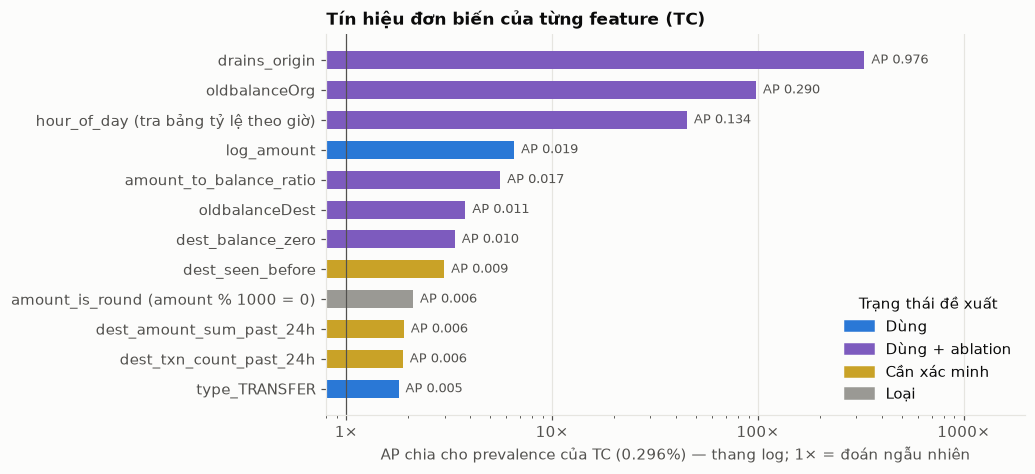

**Kết luận 2.1**
- Feature **không dính số dư** đều yếu khi đứng riêng: `log_amount` 6,5×, `type_TRANSFER` 1,8× prevalence; feature lịch sử 1,9–3,0×.
- Nhóm số dư vượt xa: `oldbalanceOrg` 98×, `drains_origin` **329×** (AP 0,976). Một feature nhị phân gần như "giải" bài toán là dấu hiệu artifact, không phải năng lực mô hình.
- `hour_of_day` có AP cao nhưng như 1.4 đã chỉ ra, đó là hệ quả của số giao dịch hợp lệ theo giờ.

In [10]:
y_tc = y[m_tc]
prev_tc = float(y_tc.mean())
amount_tc = df["amount"].to_numpy()[m_tc]; old_o = df["oldbalanceOrg"].to_numpy()[m_tc]; old_d = df["oldbalanceDest"].to_numpy()[m_tc]
hour_tc = df["hour"].to_numpy()[m_tc]
is_transfer_tc = (df["type"] == "TRANSFER").to_numpy()[m_tc]
hour_rate = hr["fraud_rate"].to_numpy()                      # tra bảng tỷ lệ theo giờ (24 giá trị, in-sample): hour_of_day không đơn điệu
drains_tc = ((amount_tc > 0) & (np.abs(amount_tc - old_o) < fr.DRAIN_TOLERANCE)).astype(float)

feat = {   # tên: (giá trị theo thứ tự các dòng TC, trạng thái dùng để tô màu)
    "type_TRANSFER": (is_transfer_tc.astype(float), "Dùng"),
    "log_amount": (np.log1p(amount_tc), "Dùng"),
    "hour_of_day (tra bảng tỷ lệ theo giờ)": (hour_rate[hour_tc], "Dùng + ablation"),
    "dest_txn_count_past_24h": (hist_cnt[m_tc].astype(float), "Cần xác minh"),
    "dest_amount_sum_past_24h": (hist_sum[m_tc], "Cần xác minh"),
    "dest_seen_before": (hist_seen[m_tc].astype(float), "Cần xác minh"),
    "oldbalanceOrg": (old_o, "Dùng + ablation"),
    "oldbalanceDest": (old_d, "Dùng + ablation"),
    "amount_to_balance_ratio": (amount_tc / (old_o + 1.0), "Dùng + ablation"),
    "drains_origin": (drains_tc, "Dùng + ablation"),
    "dest_balance_zero": ((old_d == 0).astype(float), "Dùng + ablation"),
    "amount_is_round (amount % 1000 = 0)": (((amount_tc % 1000) == 0).astype(float), "Loại"),
}
rows = []
for name, (x, status) in feat.items():
    ap_pos, ap_neg = average_precision_score(y_tc, x), average_precision_score(y_tc, -x)
    best = max(ap_pos, ap_neg)
    rows.append({"feature": name, "chiều": "+" if ap_pos >= ap_neg else "−", "AP": best, "AP / prevalence": best / prev_tc, "trạng thái": status})
ap_df = pd.DataFrame(rows).sort_values("AP / prevalence", ascending=False).reset_index(drop=True)
summary["univariate_ap"] = {"prevalence_TC": prev_tc, "rows": ap_df.to_dict("records")}
display(ap_df)

order_ = ap_df.sort_values("AP / prevalence")
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.barh(order_["feature"], order_["AP / prevalence"], height=0.6, color=[STATUS_COLOR[s] for s in order_["trạng thái"]])
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}×"))
for yy_, (v, ap_) in enumerate(zip(order_["AP / prevalence"], order_["AP"])):
    ax.text(v * 1.08, yy_, f"AP {ap_:.3f}", va="center", color=INK2, fontsize=8.5)
ax.axvline(1, color=INK2, linewidth=0.8); ax.set_xlim(0.8, ap_df["AP / prevalence"].max() * 6)
ax.set_xlabel(f"AP chia cho prevalence của TC ({prev_tc * 100:.3f}%) — thang log; 1× = đoán ngẫu nhiên")
ax.set_title("Tín hiệu đơn biến của từng feature (TC)"); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in STATUS_COLOR.values()]
ax.legend(handles, list(STATUS_COLOR), loc="lower right", title="Trạng thái đề xuất")
fig.tight_layout(); save(fig, "fig8_univariate_signal.png"); plt.show()

top = ap_df.set_index("feature")
say("**Kết luận 2.1**",
    f"- Feature **không dính số dư** đều yếu khi đứng riêng: `log_amount` {vf(top.loc['log_amount', 'AP / prevalence'], 1)}×, `type_TRANSFER` {vf(top.loc['type_TRANSFER', 'AP / prevalence'], 1)}× prevalence; feature lịch sử {vf(top.loc['dest_txn_count_past_24h', 'AP / prevalence'], 1)}–{vf(top.loc['dest_seen_before', 'AP / prevalence'], 1)}×.",
    f"- Nhóm số dư vượt xa: `oldbalanceOrg` {vf(top.loc['oldbalanceOrg', 'AP / prevalence'], 0)}×, `drains_origin` **{vf(top.loc['drains_origin', 'AP / prevalence'], 0)}×** (AP {vf(top.loc['drains_origin', 'AP'], 3)}). Một feature nhị phân gần như \"giải\" bài toán là dấu hiệu artifact, không phải năng lực mô hình.",
    "- `hour_of_day` có AP cao nhưng như 1.4 đã chỉ ra, đó là hệ quả của số giao dịch hợp lệ theo giờ.")

### 2.2 Bảng feature list

Mỗi feature có: **định nghĩa**, **trường event** cần có, **thời điểm biết** (tại lúc chấm điểm), **null policy**, **leakage risk**, **trạng thái** và **bằng chứng**. Tên trường theo transaction event của project plan (mục 7.1): `transaction_type`, `amount`, `source_account`, `destination_account`, `event_time`; hai trường số dư `source_balance_before`, `destination_balance_before` là **đề xuất mới** (cần Lead/Công Anh chốt trong `interfaces.md`).

In [11]:
d_ = tx; ba = bal
FEATURES = [
 dict(id="TX1", group="Transaction", name="type_*",
      definition="5 cột one-hot của transaction_type (type_CASH_IN … type_TRANSFER); thứ tự cố định CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER (Spark: StringIndexer stringOrderType=\"alphabetAsc\")",
      fields="transaction_type", known_at="Khi event đến",
      null_policy="Thiếu/null → từ chối (MISSING_FIELD); giá trị lạ, khác hoa/thường hoặc có khoảng trắng → từ chối (UNKNOWN_CATEGORY); sai kiểu → BAD_TYPE",
      leakage="Thấp", status="Dùng", sets="A, A+T, A+H, B",
      evidence=f"Gian lận chỉ ở TRANSFER ({vint(fraud_by_type['TRANSFER'])}; {vpct(rate_by_type['TRANSFER'], 2)}) và CASH_OUT ({vint(fraud_by_type['CASH_OUT'])}; {vpct(rate_by_type['CASH_OUT'], 2)}); 3 loại còn lại 0"),
 dict(id="TX2", group="Transaction", name="log_amount", definition="ln(1 + amount)", fields="amount", known_at="Khi event đến",
      null_policy="Thiếu → từ chối; âm → NEGATIVE_VALUE; NaN/∞ → NON_FINITE; sai kiểu (chuỗi, boolean) → BAD_TYPE; = 0 hợp lệ và gắn cờ AMOUNT_ZERO",
      leakage="Thấp (có artifact trần 10M)", status="Dùng", sets="A, A+T, A+H, B",
      evidence=f"{vint(d_['gt_10M_legit_rows'])} giao dịch hợp lệ > 10M, 0 gian lận (trần simulator); amount = 0 ở {d_['amount_zero_rows']} dòng, đều gian lận"),
 dict(id="TX3", group="Transaction", name="is_tc", definition="transaction_type ∈ {TRANSFER, CASH_OUT}; dùng làm quy tắc phạm vi (loại khác: score = 0, không alert), không đưa vào model nếu huấn luyện riêng trên TC",
      fields="transaction_type", known_at="Khi event đến", null_policy="Theo TX1", leakage="Thấp (dataset mô phỏng: ngoài TC không có gian lận)",
      status="Dùng", sets="phạm vi",
      evidence=f"100% gian lận nằm trong TC; TC có {vint(d_['tc_rows'])} dòng ({vpct(d_['tc_share_rows'])})"),
 dict(id="TX4", group="Transaction", name="amount_is_round", definition="amount chia hết cho 1.000", fields="amount", known_at="Khi event đến",
      null_policy="—", leakage="Cao (artifact trần 10M)", status="Loại", sets="—",
      evidence=f"{vint(d_['round_1000']['rows'])} dòng TC thỏa, trong đó {vint(d_['round_1000_rows_exactly_10M'])} dòng đúng bằng 10.000.000"),
 dict(id="AC1", group="Account", name="oldbalanceOrg", definition="số dư tài khoản gửi TRƯỚC giao dịch", fields="source_balance_before (trường mới, tùy chọn)",
      known_at="Khi event đến, nếu event mang trường này", null_policy="Thiếu → từ chối ở set B; tuyệt đối không điền 0 (0 mang nghĩa mạnh: gần như chắc chắn hợp lệ trong dữ liệu này); âm → NEGATIVE_VALUE",
      leakage="Cao (artifact)", status="Dùng + ablation", sets="B",
      evidence=f"oldbalanceOrg = 0: {vpct(ba['oldbalanceOrg = 0']['legit_share'])} giao dịch hợp lệ vs {vpct(ba['oldbalanceOrg = 0']['fraud_share'], 2)} gian lận; AP đơn biến {top.loc['oldbalanceOrg', 'AP / prevalence']:.0f}× prevalence"),
 dict(id="AC2", group="Account", name="oldbalanceDest", definition="số dư tài khoản nhận TRƯỚC giao dịch", fields="destination_balance_before (trường mới, tùy chọn)",
      known_at="Khi event đến, nếu event mang trường này (cần hệ thống cùng biết số dư tài khoản nhận)", null_policy="Như AC1", leakage="Cao (artifact)", status="Dùng + ablation", sets="B",
      evidence=f"oldbalanceDest = 0: {vpct(ba['oldbalanceDest = 0 (dest_balance_zero)']['fraud_share'])} gian lận vs {vpct(ba['oldbalanceDest = 0 (dest_balance_zero)']['legit_share'])} hợp lệ"),
 dict(id="AC3", group="Account", name="amount_to_balance_ratio", definition="amount / (oldbalanceOrg + 1)", fields="amount, source_balance_before", known_at="Khi event đến",
      null_policy="Như AC1; mẫu số cộng 1 nên không chia cho 0", leakage="Cao (artifact)", status="Dùng + ablation", sets="B",
      evidence=f"trung vị = {vf(summary['balance']['ratio_median_fraud'], 2)} (gian lận) vs {vnum(summary['balance']['ratio_median_legit'])} (hợp lệ)"),
 dict(id="AC4", group="Account", name="drains_origin", definition="amount > 0 và |amount − oldbalanceOrg| < 0,005 (rút sạch số dư)", fields="amount, source_balance_before", known_at="Khi event đến",
      null_policy="Như AC1; amount = 0 → 0", leakage="Cao (artifact)", status="Dùng + ablation", sets="B",
      evidence=f"{vint(ba['|amount − oldbalanceOrg| < 0,005 (drains_origin)']['rows'])} dòng, 100% gian lận ({vpct(ba['|amount − oldbalanceOrg| < 0,005 (drains_origin)']['fraud_share'])} số ca); AP {vf(top.loc['drains_origin', 'AP'], 3)}"),
 dict(id="AC5", group="Account", name="dest_balance_zero", definition="oldbalanceDest = 0", fields="destination_balance_before", known_at="Khi event đến",
      null_policy="Như AC2", leakage="Cao (artifact)", status="Dùng + ablation", sets="B",
      evidence=f"{vpct(ba['oldbalanceDest = 0 (dest_balance_zero)']['fraud_share'])} gian lận vs {vpct(ba['oldbalanceDest = 0 (dest_balance_zero)']['legit_share'])} hợp lệ"),
 dict(id="AC6", group="Account", name="dest_is_merchant", definition="destination_account bắt đầu bằng M", fields="destination_account", known_at="Khi event đến",
      null_policy="—", leakage="Thấp", status="Loại", sets="—",
      evidence=f"{vint(acct['merchant_rows'])} dòng merchant đều là PAYMENT; {acct['merchant_rows_in_TC']} dòng trong TC → đồng nhất với type = PAYMENT"),
 dict(id="HI1", group="Historical", name="dest_txn_count_past_24h", definition="số giao dịch (mọi loại) tới cùng destination_account có step trong [s−24, s−1]; cùng step không tính",
      fields="destination_account, event_time", known_at="Khi event đến; cần state theo tài khoản nhận",
      null_policy="Chưa có lịch sử → 0 (giá trị hợp lệ, không phải null); state mất sau restart là lỗi vận hành, không được âm thầm dùng 0; transaction_id trùng chỉ tính một lần",
      leakage="Trung bình (chỉ dùng dữ liệu trước thời điểm dự đoán)", status="Cần xác minh", sets="A+H, A+H+T",
      evidence=f"{vpct(hist_stats['no_txn_24h']['fraud'])} gian lận vs {vpct(hist_stats['no_txn_24h']['legit'])} hợp lệ có 0 giao dịch; state tối đa {vint(state['active_accounts_max'])} tài khoản; khởi động nguội lệch {vpct(wu['count_differs_share_first_24_steps'])} dòng TC của 24 step đầu"),
 dict(id="HI2", group="Historical", name="dest_amount_sum_past_24h", definition="tổng amount của các giao dịch trong HI1", fields="destination_account, amount, event_time",
      known_at="Như HI1", null_policy="Như HI1 (chưa có lịch sử → 0,0)", leakage="Trung bình", status="Cần xác minh", sets="A+H, A+H+T",
      evidence="Cùng nhóm tín hiệu với HI1; tính bằng cent (số nguyên) để batch và streaming khớp chính xác"),
 dict(id="HI3", group="Historical", name="dest_seen_before", definition="1 nếu từng có giao dịch tới destination_account ở step < s (toàn lịch sử), ngược lại 0",
      fields="destination_account, event_time", known_at="Như HI1; state vĩnh viễn", null_policy="Như HI1", leakage="Trung bình (phụ thuộc điểm bắt đầu của lịch sử)",
      status="Cần xác minh", sets="A+H, A+H+T",
      evidence=f"chưa từng thấy: {vpct(hist_stats['never_seen']['fraud'])} gian lận vs {vpct(hist_stats['never_seen']['legit'])} hợp lệ; state {vint(state['accounts_lifetime'])} tài khoản; khởi động nguội sai {vpct(wu['seen_differs_share_test_tc'])} dòng TC của giai đoạn test"),
 dict(id="HI4", group="Historical", name="orig_txn_count_past", definition="lịch sử theo tài khoản gửi", fields="source_account", known_at="Cần state", null_policy="—",
      leakage="Thấp", status="Loại", sets="—", evidence=f"chỉ {vint(acct['orig_repeated_accounts'])} tài khoản gửi xuất hiện > 1 lần ({vpct(acct['orig_repeated_row_share'], 2)} số dòng)"),
 dict(id="HI5", group="Historical", name="dest_has_sent_before", definition="tài khoản nhận từng là tài khoản gửi ở step trước", fields="source_account, destination_account", known_at="Cần state",
      null_policy="—", leakage="Thấp", status="Loại", sets="—",
      evidence=f"{vpct(acct['dest_has_sent_before_TC']['fraud'], 2)} gian lận vs {vpct(acct['dest_has_sent_before_TC']['legit'], 2)} hợp lệ: không có tín hiệu"),
 dict(id="HI6", group="Historical", name="matching_transfer_same_step", definition="CASH_OUT có TRANSFER cùng amount trong cùng step", fields="amount, event_time", known_at="Cần state, phụ thuộc thứ tự trong step",
      null_policy="—", leakage="Cao (artifact)", status="Loại", sets="—", evidence="W1: 4.078/4.097 TRANSFER gian lận có cặp như vậy; kết quả phụ thuộc thứ tự trong cùng step nên batch và streaming không nhất quán"),
 dict(id="TM1", group="Time", name="hour_of_day", definition="(step − 1) mod 24; step = floor((event_time − T0) / 1 giờ) + 1 tính bằng số học UTC", fields="event_time (hoặc step ở batch)", known_at="Khi event đến",
      null_policy="Thiếu cả step lẫn event_time → từ chối; event_time phải có múi giờ, trước T0 hoặc không phải ISO-8601 → BAD_TIMESTAMP; step và event_time mâu thuẫn → INCONSISTENT_TIME",
      leakage="Trung bình (artifact)", status="Dùng + ablation", sets="A+T, A+H+T",
      evidence=f"gian lận phẳng {vpct(hour_stats['fraud_share_per_hour_min'])}–{vpct(hour_stats['fraud_share_per_hour_max'])} mỗi giờ; tỷ lệ {vpct(hour_stats['fraud_rate_min'], 2)}–{vpct(hour_stats['fraud_rate_max'])} do giao dịch hợp lệ ban đêm co lại"),
 dict(id="TM2", group="Time", name="day_index, step", definition="ngày thứ mấy; chỉ số giờ tuyệt đối (step thô)", fields="event_time", known_at="Khi event đến", null_policy="—",
      leakage="Cao (không tổng quát cho tương lai)", status="Loại", sets="—", evidence="Phân phối giao dịch hợp lệ đổi mạnh theo ngày (xem Bước 3); chỉ dùng step để tạo event_time và split"),
 dict(id="EX1", group="Loại tuyệt đối", name="newbalanceOrig, newbalanceDest, error_balance_*", definition="số dư SAU giao dịch và các feature suy ra", fields="(không được có trong event)",
      known_at="Chỉ biết sau khi giao dịch xử lý xong", null_policy="Event có trường này → từ chối (FORBIDDEN_FIELD)", leakage="Cao", status="Loại", sets="—",
      evidence="W1: 99,5% gian lận khớp old − amount = new so với 9,5% hợp lệ"),
 dict(id="EX2", group="Loại tuyệt đối", name="isFlaggedFraud", definition="cờ của rule trong simulator", fields="(không được có trong event)", known_at="Là đầu ra của một rule",
      null_policy="Event có trường này → từ chối", leakage="Cao", status="Loại", sets="—", evidence="W1: 16 dòng, 100% là gian lận, recall 0,19%"),
 dict(id="EX3", group="Loại tuyệt đối", name="isFraud, is_fraud, label", definition="nhãn ground truth và các biến thể tên", fields="(không được có trong event)", known_at="Chỉ có ở đường đánh giá",
      null_policy="Event có trường này → từ chối", leakage="—", status="Loại", sets="—", evidence="Tách khỏi scoring input theo label-definition.md mục 4"),
]
feature_table = pd.DataFrame(FEATURES)
summary["feature_table"] = FEATURES
summary["feature_sets"] = {k: list(v) for k, v in fr.FEATURE_SETS.items()}
with pd.option_context("display.max_colwidth", None):
    display(feature_table[["id", "group", "name", "definition", "leakage", "status", "sets"]])
print(feature_table.groupby("status").size().to_string())

,id,group,name,definition,leakage,status,sets
0,TX1,Transaction,type_*,"5 cột one-hot của transaction_type (type_CASH_IN … type_TRANSFER); thứ tự cố định CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER (Spark: StringIndexer stringOrderType=""alphabetAsc"")",Thấp,Dùng,"A, A+T, A+H, B"
1,TX2,Transaction,log_amount,ln(1 + amount),Thấp (có artifact trần 10M),Dùng,"A, A+T, A+H, B"
2,TX3,Transaction,is_tc,"transaction_type ∈ {TRANSFER, CASH_OUT}; dùng làm quy tắc phạm vi (loại khác: score = 0, không alert), không đưa vào model nếu huấn luyện riêng trên TC",Thấp (dataset mô phỏng: ngoài TC không có gian lận),Dùng,phạm vi
3,TX4,Transaction,amount_is_round,amount chia hết cho 1.000,Cao (artifact trần 10M),Loại,—
4,AC1,Account,oldbalanceOrg,số dư tài khoản gửi TRƯỚC giao dịch,Cao (artifact),Dùng + ablation,B
5,AC2,Account,oldbalanceDest,số dư tài khoản nhận TRƯỚC giao dịch,Cao (artifact),Dùng + ablation,B
6,AC3,Account,amount_to_balance_ratio,amount / (oldbalanceOrg + 1),Cao (artifact),Dùng + ablation,B
7,AC4,Account,drains_origin,"amount > 0 và |amount − oldbalanceOrg| < 0,005 (rút sạch số dư)",Cao (artifact),Dùng + ablation,B
8,AC5,Account,dest_balance_zero,oldbalanceDest = 0,Cao (artifact),Dùng + ablation,B
9,AC6,Account,dest_is_merchant,destination_account bắt đầu bằng M,Thấp,Loại,—


status
Cần xác minh       3
Dùng               3
Dùng + ablation    6
Loại               9


### 2.3 Đối chiếu đặc tả chạy được với phép tính hàng loạt

Lấy mẫu ngẫu nhiên 3.000 dòng (cộng 16 dòng `amount = 0`) và với 300 giao dịch gửi tới các tài khoản nhận khác nhau, tính feature bằng `src/evaluation/feature_reference.py` (từng event một, đúng như Spark sẽ phải làm) rồi so với giá trị vector hóa ở trên.

In [12]:
rng = np.random.default_rng(SEED)
sample = np.unique(np.concatenate([rng.choice(n, 3000, replace=False), np.flatnonzero(df["amount"].to_numpy() == 0)]))
sub = df.iloc[sample]
types = sub["type"].astype(str).to_numpy()
mism = []
for i, (t, a, s, o, dd) in enumerate(zip(types, sub["amount"], sub["step"], sub["oldbalanceOrg"], sub["oldbalanceDest"])):
    ev = {"transaction_type": t, "amount": float(a), "step": int(s), "source_balance_before": float(o), "destination_balance_before": float(dd)}
    b_, t_ = fr.stateless_features(ev, "B"), fr.stateless_features(ev, "A+T")
    want = {"log_amount": np.log1p(a), "oldbalanceOrg": o, "oldbalanceDest": dd, "amount_to_balance_ratio": a / (o + 1.0),
            "drains_origin": float(a > 0 and abs(a - o) < fr.DRAIN_TOLERANCE), "dest_balance_zero": float(dd == 0),
            "hour_of_day": float((s - 1) % 24)}
    got = {**b_, "hour_of_day": t_["hour_of_day"]}
    bad = [k for k, v in want.items() if not np.isclose(got[k], v, rtol=1e-12, atol=1e-12)]
    if bad or got[f"type_{t}"] != 1.0 or sum(got[f"type_{x}"] for x in fr.TRANSACTION_TYPES) != 1.0:
        mism.append((int(sample[i]), bad))
print(f"Feature không trạng thái: {len(sample)} dòng, {len(mism)} dòng lệch", mism[:3])

# Feature lịch sử: với mỗi tài khoản nhận được chọn, đưa TOÀN BỘ giao dịch tới tài khoản đó cho đặc tả và so với kết quả hàng loạt
dest_order = np.argsort(dest, kind="stable"); dest_sorted = dest[dest_order]
targets = rng.choice(np.flatnonzero(m_tc), 300, replace=False)
bad_hist = []
for r in targets:
    d = dest[r]
    rows_d = dest_order[np.searchsorted(dest_sorted, d, "left"):np.searchsorted(dest_sorted, d, "right")]
    events = [{"transaction_id": f"txn_{int(j):07d}", "destination_account": int(d), "step": int(step[j]), "amount": float(df["amount"].iat[j])} for j in rows_d]
    got = fr.historical_features(events)[f"txn_{int(r):07d}"]
    want = (hist_cnt[r], hist_sum[r], float(hist_seen[r]))
    if not (got["dest_txn_count_past_24h"] == want[0] and abs(got["dest_amount_sum_past_24h"] - want[1]) < 1e-3 and got["dest_seen_before"] == want[2]):
        bad_hist.append((int(r), got, want))
print(f"Feature lịch sử: {len(targets)} giao dịch, {len(bad_hist)} lệch", bad_hist[:2])
summary["reference_crosscheck"] = {"stateless_rows": int(len(sample)), "stateless_mismatches": len(mism),
                                   "history_rows": int(len(targets)), "history_mismatches": len(bad_hist)}
assert not mism and not bad_hist

Feature không trạng thái: 3016 dòng, 0 dòng lệch []


Feature lịch sử: 300 giao dịch, 0 lệch []


### 2.4 Kiểm tra sơ bộ các feature set trên split theo thời gian

Huấn luyện một `HistGradientBoostingClassifier` trên TC của giai đoạn **train (step 1–323)** và đo Average Precision (AP) trên **val (324–378)** và **test (379–743)**. Mục đích chỉ là kiểm chứng giả thuyết của feature list: mỗi nhóm feature đóng góp bao nhiêu và set nào bị artifact chi phối. Đây **không phải** kết quả W3 (Đạt huấn luyện, Thái đánh giá): chưa tune, chưa có threshold, chưa dùng Logistic Regression/Random Forest của Spark MLlib.

Định nghĩa các set: **A** = type + log_amount · **A+T** = A + hour_of_day · **A+H** = A + 3 feature lịch sử · **A+H+T** = A+H + hour_of_day · **B** = A + 5 feature số dư.

**Lưu ý phương pháp.** Kết quả của dạng kiểm tra này rất nhạy với cấu hình mô hình (bảng đầu tiên bên dưới chứng minh điều đó), nên: dùng cấu hình có regularization làm cấu hình **chính**, đối chiếu với một cấu hình **phụ** khác (nông hơn, learning rate nhỏ hơn), và báo cáo mức chênh lệch giữa hai cấu hình.

,cấu hình,set,số vòng thực tế,AP val,AP test,% dòng val cùng score tối đa
0,mặc định (early stopping tự động),A,11,0.00818545,0.056638,4.2057e-05
1,mặc định (early stopping tự động),B,15,0.991213,0.999243,0.00132947
2,"không regularization, 100 vòng",A,100,0.112053,0.240734,0.000331783
3,"không regularization, 100 vòng",B,100,0.00616718,0.0360503,0.0148251
4,chính,A,100,0.162759,0.269922,7.24314e-05
5,chính,B,100,1,0.999785,0.00022664


,features,AP val (chính),AP test (chính),AP val (phụ),AP test (phụ),val / prevalence,test / prevalence,lệch giữa 2 cấu hình
set,,,,,,,,
A,2,0.162759,0.269922,0.161501,0.270701,123.509,26.3132,0.00125811
A+T,3,0.325574,0.416892,0.334178,0.423584,247.061,40.6405,0.00860444
A+H,5,0.181988,0.434048,0.179509,0.431873,138.102,42.3129,0.00247988
A+H+T,6,0.357248,0.492284,0.368459,0.523124,271.098,47.9901,0.0308397
B,7,1,0.999785,1,0.999973,758.849,97.4636,0.00018763


,AP val,AP test
A,0.162759,0.269922
A_without_amount_ge_9.9M,0.0778794,0.116779
only_log_amount,0.00455096,0.0759614
only_type_TRANSFER,0.00234873,0.0176133


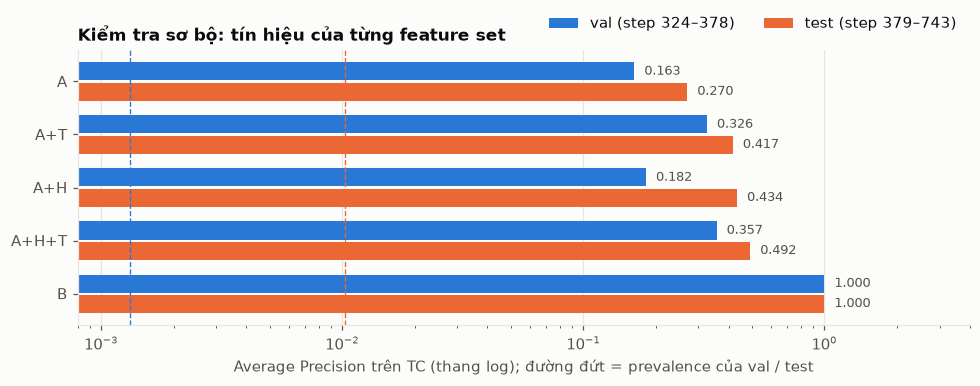

**Kết luận 2.4**
- **Kết quả rất nhạy với cấu hình.** Early stopping mặc định dừng sau 11 vòng và cho AP val của set A chỉ 0,008; huấn luyện đủ vòng có regularization cho 0,163. Không regularization thì set B chỉ đạt AP val 0,006 (1,5% dòng val cùng mang score tối đa nên bị hòa điểm) trong khi cấu hình chính cho 1,000. → khi Đạt huấn luyện ở W3 phải đặt rõ số vòng/regularization và không dựa vào early stopping mặc định.
- Hai cấu hình có regularization (chính và phụ) lệch nhau tối đa **0,031** AP trên mọi set, nên các con số dưới đây đủ ổn định cho mục đích xếp hạng.
- **Set A có tín hiệu vừa phải:** AP 0,163 (val, prevalence 0,13%, ≈ 124×) và 0,270 (test, prevalence 1,03%, ≈ 26×). Tín hiệu đến từ **tương tác type × amount**: riêng `log_amount` chỉ đạt 0,005/0,076, riêng `type` đạt 0,002/0,018. Bỏ 5.707 dòng có amount ≥ 9,9M (vùng sát trần 10M; chỉ 10/564 ca gian lận của val) làm AP giảm còn 0,078/0,117, tức **mất khoảng một nửa**: phần đáng kể điểm AP của A dựa vào vùng trần 10M (artifact); phần còn lại vẫn cao hơn prevalence nhiều lần nhờ tương tác type × amount.
- Thêm `hour_of_day` (A+T: 0,326/0,417) hoặc feature lịch sử (A+H: 0,182/0,434) đều tăng AP, A+H+T cao nhất trong các set không có số dư (0,357/0,492); nhưng cả hai nguồn tăng đều là artifact hoặc cần xác minh (1.3, 1.4).
- **Set B đạt AP 1,000 (val) và 1,000 (test):** gần như hoàn hảo nhờ artifact số dư; nếu báo cáo chỉ nêu con số này, nó không phản ánh khả năng phát hiện gian lận thật.
- → W3 phải báo cáo **đồng thời A, A+T, A+H, A+H+T, B**, nêu rõ phần tín hiệu đến từ artifact và giới hạn của dữ liệu mô phỏng.

In [13]:
X = pd.DataFrame({
    "type_TRANSFER": is_transfer_tc.astype("int8"),
    "log_amount": np.log1p(amount_tc),
    "hour_of_day": hour_tc,
    "dest_txn_count_past_24h": hist_cnt[m_tc].astype("int32"),
    "dest_amount_sum_past_24h": hist_sum[m_tc],
    "dest_seen_before": hist_seen[m_tc].astype("int8"),
    "oldbalanceOrg": old_o, "oldbalanceDest": old_d,
    "amount_to_balance_ratio": amount_tc / (old_o + 1.0),
    "drains_origin": drains_tc.astype("int8"),
    "dest_balance_zero": (old_d == 0).astype("int8"),
})
split_tc_ids = df["split"].to_numpy()[m_tc]
CORE = ["type_TRANSFER", "log_amount"]; HIST = ["dest_txn_count_past_24h", "dest_amount_sum_past_24h", "dest_seen_before"]
SETS = {"A": CORE, "A+T": CORE + ["hour_of_day"], "A+H": CORE + HIST, "A+H+T": CORE + HIST + ["hour_of_day"],
        "B": CORE + ["oldbalanceOrg", "oldbalanceDest", "amount_to_balance_ratio", "drains_origin", "dest_balance_zero"]}
tr_, va_, te_ = split_tc_ids == 0, split_tc_ids == 1, split_tc_ids == 2
prev = {"val": float(y_tc[va_].mean()), "test": float(y_tc[te_].mean())}


def fit_eval(cols, cfg, keep=None):
    keep = np.ones(len(X), dtype=bool) if keep is None else keep
    clf = HistGradientBoostingClassifier(**cfg).fit(X.loc[tr_ & keep, cols], y_tc[tr_ & keep])
    out = {}
    for nm, m in (("val", va_), ("test", te_)):
        p = clf.predict_proba(X.loc[m & keep, cols])[:, 1]
        out[nm] = float(average_precision_score(y_tc[m & keep], p)); out[f"{nm}_scores"] = p
        out[f"{nm}_share_at_max"] = float((p == p.max()).mean())
    out["n_iter"] = int(clf.n_iter_)
    return out


# (1) Độ nhạy theo cấu hình: hai cấu hình "xấu" so với cấu hình chính (chỉ set A và B)
CONFIGS = {
    "chính": dict(max_iter=100, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0, early_stopping=False, random_state=SEED),
    "phụ": dict(max_iter=50, learning_rate=0.05, max_depth=6, min_samples_leaf=200, l2_regularization=1.0, early_stopping=False, random_state=SEED),
}
BAD = {
    "mặc định (early stopping tự động)": dict(max_iter=100, random_state=SEED),
    "không regularization, 100 vòng": dict(max_iter=100, early_stopping=False, random_state=SEED),
}
rows = []
for cname, cfg in {**BAD, "chính": CONFIGS["chính"]}.items():
    for sname in ("A", "B"):
        r = fit_eval(SETS[sname], cfg)
        rows.append({"cấu hình": cname, "set": sname, "số vòng thực tế": r["n_iter"], "AP val": r["val"], "AP test": r["test"],
                     "% dòng val cùng score tối đa": r["val_share_at_max"]})
sens = pd.DataFrame(rows)
summary["config_sensitivity"] = sens.to_dict("records")
display(sens)

# (2) Kết quả chính cho cả 5 set, kèm cấu hình phụ để đo độ ổn định
val_scores, sanity = {}, []
for name, cols in SETS.items():
    row = {"set": name, "features": len(cols)}
    for cname, cfg in CONFIGS.items():
        r = fit_eval(cols, cfg)
        row[f"AP val ({cname})"], row[f"AP test ({cname})"] = r["val"], r["test"]
        if cname == "chính":
            val_scores[name] = r["val_scores"]
    sanity.append(row)
sanity_df = pd.DataFrame(sanity).set_index("set")
sanity_df["val / prevalence"] = sanity_df["AP val (chính)"] / prev["val"]
sanity_df["test / prevalence"] = sanity_df["AP test (chính)"] / prev["test"]
sanity_df["lệch giữa 2 cấu hình"] = np.maximum((sanity_df["AP val (chính)"] - sanity_df["AP val (phụ)"]).abs(),
                                               (sanity_df["AP test (chính)"] - sanity_df["AP test (phụ)"]).abs())
display(sanity_df)

# (3) Tín hiệu của set A đến từ đâu? Bỏ vùng amount sát trần 10M; thử từng feature riêng
near_cap = amount_tc >= 9.9e6
diag = {
    "A": {k: v for k, v in fit_eval(SETS["A"], CONFIGS["chính"]).items() if k in ("val", "test")},
    "A_without_amount_ge_9.9M": {k: v for k, v in fit_eval(SETS["A"], CONFIGS["chính"], ~near_cap).items() if k in ("val", "test")},
    "only_log_amount": {k: v for k, v in fit_eval(["log_amount"], CONFIGS["chính"]).items() if k in ("val", "test")},
    "only_type_TRANSFER": {k: v for k, v in fit_eval(["type_TRANSFER"], CONFIGS["chính"]).items() if k in ("val", "test")},
    "rows_amount_ge_9.9M": int(near_cap.sum()), "fraud_rows_amount_ge_9.9M": int((near_cap & (y_tc == 1)).sum()),
    "val_fraud_rows": int(((y_tc == 1) & va_).sum()), "val_fraud_rows_amount_ge_9.9M": int(((y_tc == 1) & va_ & near_cap).sum()),
}
display(pd.DataFrame({k: v for k, v in diag.items() if isinstance(v, dict)}).T.rename(columns={"val": "AP val", "test": "AP test"}))

summary["feature_set_sanity_check"] = {
    "prevalence_TC": prev, "rows": sanity_df.reset_index().to_dict("records"), "diagnostics_set_A": diag,
    "model_main": "HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0, early_stopping=False, random_state=42)",
    "model_alt": "HistGradientBoostingClassifier(max_iter=50, learning_rate=0.05, max_depth=6, min_samples_leaf=200, l2_regularization=1.0, early_stopping=False, random_state=42)"}

fig, ax = plt.subplots(figsize=(9, 3.6))
yy_ = np.arange(len(sanity_df))[::-1]; h_ = 0.34
ax.barh(yy_ + h_ / 2 + 0.02, sanity_df["AP val (chính)"], height=h_, color=LEGIT, label="val (step 324–378)")
ax.barh(yy_ - h_ / 2 - 0.02, sanity_df["AP test (chính)"], height=h_, color=FRAUD, label="test (step 379–743)")
for yv, (_, r) in zip(yy_, sanity_df.iterrows()):
    ax.text(r["AP val (chính)"] * 1.1, yv + h_ / 2 + 0.02, f"{r['AP val (chính)']:.3f}", va="center", color=INK2, fontsize=8.5)
    ax.text(r["AP test (chính)"] * 1.1, yv - h_ / 2 - 0.02, f"{r['AP test (chính)']:.3f}", va="center", color=INK2, fontsize=8.5)
ax.set_yticks(yy_); ax.set_yticklabels(sanity_df.index); ax.set_xscale("log"); ax.set_xlim(0.0008, 4)
ax.axvline(prev["val"], color=LEGIT, linewidth=0.9, linestyle="--"); ax.axvline(prev["test"], color=FRAUD, linewidth=0.9, linestyle="--")
ax.set_xlabel("Average Precision trên TC (thang log); đường đứt = prevalence của val / test")
ax.set_title("Kiểm tra sơ bộ: tín hiệu của từng feature set"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", ncol=2, bbox_to_anchor=(1, 1.02))
fig.tight_layout(); save(fig, "fig9_feature_sets.png"); plt.show()

s = sanity_df; dg = diag
sa = sens.set_index(["cấu hình", "set"])
say("**Kết luận 2.4**",
    f"- **Kết quả rất nhạy với cấu hình.** Early stopping mặc định dừng sau {int(sa.loc[('mặc định (early stopping tự động)', 'A'), 'số vòng thực tế'])} vòng và cho AP val của set A chỉ {vf(sa.loc[('mặc định (early stopping tự động)', 'A'), 'AP val'], 3)}; huấn luyện đủ vòng có regularization cho {vf(sa.loc[('chính', 'A'), 'AP val'], 3)}. Không regularization thì set B chỉ đạt AP val {vf(sa.loc[('không regularization, 100 vòng', 'B'), 'AP val'], 3)} ({vpct(sa.loc[('không regularization, 100 vòng', 'B'), '% dòng val cùng score tối đa'], 1)} dòng val cùng mang score tối đa nên bị hòa điểm) trong khi cấu hình chính cho {vf(sa.loc[('chính', 'B'), 'AP val'], 3)}. → khi Đạt huấn luyện ở W3 phải đặt rõ số vòng/regularization và không dựa vào early stopping mặc định.",
    f"- Hai cấu hình có regularization (chính và phụ) lệch nhau tối đa **{vf(s['lệch giữa 2 cấu hình'].max(), 3)}** AP trên mọi set, nên các con số dưới đây đủ ổn định cho mục đích xếp hạng.",
    f"- **Set A có tín hiệu vừa phải:** AP {vf(s.loc['A', 'AP val (chính)'], 3)} (val, prevalence {vpct(prev['val'], 2)}, ≈ {s.loc['A', 'val / prevalence']:.0f}×) và {vf(s.loc['A', 'AP test (chính)'], 3)} (test, prevalence {vpct(prev['test'], 2)}, ≈ {s.loc['A', 'test / prevalence']:.0f}×). Tín hiệu đến từ **tương tác type × amount**: riêng `log_amount` chỉ đạt {vf(dg['only_log_amount']['val'], 3)}/{vf(dg['only_log_amount']['test'], 3)}, riêng `type` đạt {vf(dg['only_type_TRANSFER']['val'], 3)}/{vf(dg['only_type_TRANSFER']['test'], 3)}. Bỏ {vint(dg['rows_amount_ge_9.9M'])} dòng có amount ≥ 9,9M (vùng sát trần 10M; chỉ {dg['val_fraud_rows_amount_ge_9.9M']}/{dg['val_fraud_rows']} ca gian lận của val) làm AP giảm còn {vf(dg['A_without_amount_ge_9.9M']['val'], 3)}/{vf(dg['A_without_amount_ge_9.9M']['test'], 3)}, tức **mất khoảng một nửa**: phần đáng kể điểm AP của A dựa vào vùng trần 10M (artifact); phần còn lại vẫn cao hơn prevalence nhiều lần nhờ tương tác type × amount.",
    f"- Thêm `hour_of_day` (A+T: {vf(s.loc['A+T', 'AP val (chính)'], 3)}/{vf(s.loc['A+T', 'AP test (chính)'], 3)}) hoặc feature lịch sử (A+H: {vf(s.loc['A+H', 'AP val (chính)'], 3)}/{vf(s.loc['A+H', 'AP test (chính)'], 3)}) đều tăng AP, A+H+T cao nhất trong các set không có số dư ({vf(s.loc['A+H+T', 'AP val (chính)'], 3)}/{vf(s.loc['A+H+T', 'AP test (chính)'], 3)}); nhưng cả hai nguồn tăng đều là artifact hoặc cần xác minh (1.3, 1.4).",
    f"- **Set B đạt AP {vf(s.loc['B', 'AP val (chính)'], 3)} (val) và {vf(s.loc['B', 'AP test (chính)'], 3)} (test):** gần như hoàn hảo nhờ artifact số dư; nếu báo cáo chỉ nêu con số này, nó không phản ánh khả năng phát hiện gian lận thật.",
    "- → W3 phải báo cáo **đồng thời A, A+T, A+H, A+H+T, B**, nêu rõ phần tín hiệu đến từ artifact và giới hạn của dữ liệu mô phỏng.")

## Bước 3 — Đề xuất split train / validation / test

Kế hoạch: *đề xuất split train/validation/test; cân nhắc split theo thời gian*. W1 đã đề xuất cắt theo `step` (train 1–323, val 324–378, test 379–743, ~70/15/15 số dòng). W2 kiểm tra lại đề xuất đó trên dữ liệu thật ở ba điểm: (a) phân phối theo **ngày** (có ổn định để làm phép đánh giá theo cửa sổ thời gian không?), (b) prevalence từng phần với quần thể **toàn bộ giao dịch** và **chỉ TC**, (c) phương án phụ stratified random (seed 42).

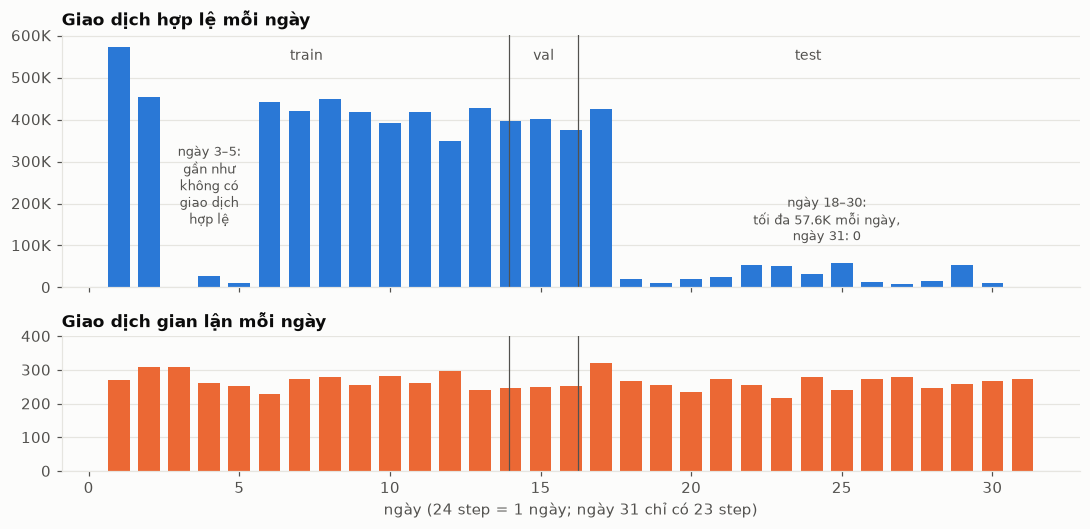

day,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,...,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
rows,574255,455238,1070,28240,9789,441005,420583,449637,417919,392945,417859,349776,428583,397876,401282,...,425766,20999,11300,19727,24593,53437,51012,32709,57853,13885,8578,14661,54890,11287,272
fraud,271,309,310,262,252,228,272,278,255,282,262,298,242,246,250,...,320,268,256,236,272,256,216,280,240,272,280,248,260,268,272
legit,573984,454929,760,27978,9537,440777,420311,449359,417664,392663,417597,349478,428341,397630,401032,...,425446,20731,11044,19491,24321,53181,50796,32429,57613,13613,8298,14413,54630,11019,0


In [14]:
daily = df.groupby("day").agg(rows=("isFraud", "size"), fraud=("isFraud", "sum"))
daily["legit"] = daily["rows"] - daily["fraud"]
xb1, xb2 = T1 / 24 + 0.5, T2 / 24 + 0.5                 # ranh giới split theo trục ngày (cột của ngày d nằm ở d ± 0,5)

fig, axes = plt.subplots(2, 1, figsize=(10, 4.9), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
axes[0].bar(daily.index, daily["legit"], width=0.72, color=LEGIT); axes[0].set_title("Giao dịch hợp lệ mỗi ngày")
axes[1].bar(daily.index, daily["fraud"], width=0.72, color=FRAUD); axes[1].set_title("Giao dịch gian lận mỗi ngày")
axes[1].set_ylim(0, daily["fraud"].max() * 1.25); axes[1].set_xlabel("ngày (24 step = 1 ngày; ngày 31 chỉ có 23 step)")
for ax in axes:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact)); ax.grid(axis="x", visible=False)
    for xb in (xb1, xb2): ax.axvline(xb, color=INK2, linewidth=0.8)
top_y = axes[0].get_ylim()[1] * 0.9
for xx, lab in [((0.5 + xb1) / 2, "train"), ((xb1 + xb2) / 2, "val"), ((xb2 + 31.5) / 2, "test")]:
    axes[0].text(xx, top_y, lab, ha="center", color=INK2, fontsize=9)
axes[0].text(4, daily["legit"].max() * 0.42, "ngày 3–5:\ngần như\nkhông có\ngiao dịch\nhợp lệ", ha="center", va="center", color=INK2, fontsize=8.5)
axes[0].text(24.5, daily["legit"].max() * 0.28, "ngày 18–30:\ntối đa " + compact(daily.loc[18:30, "legit"].max()) + " mỗi ngày,\nngày 31: 0", ha="center", va="center", color=INK2, fontsize=8.5)
fig.tight_layout(); save(fig, "fig10_daily_volume.png"); plt.show()

heavy = daily.loc[[1, 2] + list(range(6, 18)), "legit"]       # các ngày có khối lượng giao dịch hợp lệ bình thường
late = daily.loc[18:30]                                         # ngày 31 chỉ có 23 step và không có giao dịch hợp lệ, nêu riêng
test_win = df[df["step"] >= T2 + 1].assign(win=lambda d: (d["step"] - (T2 + 1)) // 24).groupby("win").agg(rows=("isFraud", "size"), fraud=("isFraud", "sum"))
test_win["legit"] = test_win["rows"] - test_win["fraud"]
per_step = df.groupby("step")["isFraud"].agg(rows="size", fraud="sum")
only_fraud_steps = per_step.index[per_step["rows"] == per_step["fraud"]]
assert len(only_fraud_steps) == W1["time"]["steps_with_only_fraud"]          # khớp số liệu W1
time_structure = {
    "legit_per_day_heavy_days_min_max": [int(heavy.min()), int(heavy.max())],
    "legit_per_day_days_3_5": [int(daily.loc[d, "legit"]) for d in (3, 4, 5)],
    "legit_per_day_days_18_30_min_max": [int(late["legit"].min()), int(late["legit"].max())],
    "legit_day_31": int(daily.loc[31, "legit"]),
    "fraud_per_day_min_max": [int(daily["fraud"].min()), int(daily["fraud"].max())],
    "test_windows_24_steps": int(len(test_win)), "test_windows_without_legit": int((test_win["legit"] == 0).sum()),
    "test_windows_min_fraud": int(test_win["fraud"].min()),
    "test_last_window_steps": int(df["step"].max() - (T2 + 1 + 24 * (len(test_win) - 1)) + 1),
    "steps_only_fraud": int(len(only_fraud_steps)), "only_fraud_steps_first": int(only_fraud_steps.min()),
    "only_fraud_steps_last": int(only_fraud_steps.max()),
}
summary["time_structure"] = time_structure
display(daily.T)

In [15]:
def split_table(frame):
    t = frame.groupby("split").agg(step_from=("step", "min"), step_to=("step", "max"), rows=("isFraud", "size"), fraud=("isFraud", "sum"))
    t.index = SPLITS
    t["prevalence"] = t["fraud"] / t["rows"]; t["share_rows"] = t["rows"] / t["rows"].sum(); t["share_fraud"] = t["fraud"] / t["fraud"].sum()
    return t


split_all, split_tc = split_table(df), split_table(tc)
print("Quần thể P1: toàn bộ giao dịch (đánh giá cấp hệ thống)"); display(split_all)
print("Quần thể P2: chỉ TRANSFER + CASH_OUT (đánh giá cấp model)"); display(split_tc)

# Phương án phụ: stratified random 70/15/15 theo từng lớp, seed 42 (CHỈ dùng được với feature không lịch sử)
rng = np.random.default_rng(SEED)
rand_split = np.empty(n, dtype=np.int8)
for cls in (0, 1):
    idx = np.flatnonzero(y == cls); rng.shuffle(idx)
    c1, c2 = int(0.70 * len(idx)), int(0.85 * len(idx))
    rand_split[idx[:c1]], rand_split[idx[c1:c2]], rand_split[idx[c2:]] = 0, 1, 2
rand_tab = pd.DataFrame({"rows": np.bincount(rand_split), "fraud": np.bincount(rand_split, weights=y).astype(int)}, index=SPLITS)
rand_tab["prevalence"] = rand_tab["fraud"] / rand_tab["rows"]
print("Phương án phụ: stratified random (seed 42)"); display(rand_tab)

summary["split"] = {"cuts": {"train_to": T1, "val_to": T2},
                    "all_types": split_all.reset_index(names="split").to_dict("records"),
                    "tc_only": split_tc.reset_index(names="split").to_dict("records"),
                    "stratified_random_seed42": rand_tab.reset_index(names="split").to_dict("records")}
ts = time_structure
say("**Kết luận Bước 3**",
    f"- **Giữ split theo thời gian của W1** (train 1–323 / val 324–378 / test 379–743) làm protocol chính: khớp kịch bản \"học quá khứ, chấm điểm tương lai\" của hệ thống và không làm rò thông tin tương lai vào feature lịch sử. Stratified random chỉ là phương án phụ, **không dùng với feature lịch sử**.",
    f"- Prevalence thay đổi mạnh theo thời gian: toàn bộ giao dịch {vpct(split_all.loc['train', 'prevalence'], 3)} → {vpct(split_all.loc['val', 'prevalence'], 3)} → {vpct(split_all.loc['test', 'prevalence'], 3)}; chỉ TC {vpct(split_tc.loc['train', 'prevalence'], 3)} → {vpct(split_tc.loc['val', 'prevalence'], 3)} → {vpct(split_tc.loc['test', 'prevalence'], 3)}. Test chứa {vpct(split_all.loc['test', 'share_fraud'])} số ca gian lận chỉ trong {vpct(split_all.loc['test', 'share_rows'])} số dòng. Precision trên test cao hơn val một phần vì prevalence → luôn đọc PR-AUC so với prevalence của đúng split.",
    f"- **Lý do của sự dịch chuyển:** giao dịch hợp lệ {vint(ts['legit_per_day_heavy_days_min_max'][0])}–{vint(ts['legit_per_day_heavy_days_min_max'][1])} mỗi ngày ở ngày 1–2 và 6–17 (trừ ngày 3–5: {vint(ts['legit_per_day_days_3_5'][0])}/{vint(ts['legit_per_day_days_3_5'][1])}/{vint(ts['legit_per_day_days_3_5'][2])}), rồi chỉ còn {vint(ts['legit_per_day_days_18_30_min_max'][0])}–{vint(ts['legit_per_day_days_18_30_min_max'][1])} mỗi ngày ở ngày 18–30 và **{ts['legit_day_31']} ở ngày 31**; gian lận đều {ts['fraud_per_day_min_max'][0]}–{ts['fraud_per_day_min_max'][1]} ca mỗi ngày. Đây là đặc tính của simulator.",
    f"- Streaming replay giai đoạn test chia được {ts['test_windows_24_steps']} cửa sổ 24 step; {ts['test_windows_without_legit']} cửa sổ (cửa sổ cuối, chỉ {ts['test_last_window_steps']} step) không có giao dịch hợp lệ nào nên precision theo cửa sổ vô nghĩa ở đó; cửa sổ nào cũng có ít nhất {ts['test_windows_min_fraud']} ca gian lận.",
    f"- **Quần thể đánh giá:** báo cáo chính trên P1 (toàn bộ giao dịch, đúng như hệ thống chấm điểm), báo cáo phụ trên P2. Nếu loại ngoài TC được gán score thấp nhất thì PR-AUC của P1 và P2 **bằng nhau**; chỉ prevalence dùng làm mốc so sánh là khác nhau (P1 thấp hơn {vnum(n / len(tc), 1)} lần), nên mọi bảng phải ghi rõ quần thể.")

Quần thể P1: toàn bộ giao dịch (đánh giá cấp hệ thống)


,step_from,step_to,rows,fraud,prevalence,share_rows,share_fraud
train,1,323,4463587,3643,0.00081616,0.701533,0.443565
val,324,378,980416,564,0.000575266,0.15409,0.0686716
test,379,743,918617,4006,0.0043609,0.144377,0.487763


Quần thể P2: chỉ TRANSFER + CASH_OUT (đánh giá cấp model)


,step_from,step_to,rows,fraud,prevalence,share_rows,share_fraud
train,1,323,1951895,3643,0.00186639,0.704551,0.443565
val,324,378,427991,564,0.00131778,0.154487,0.0686716
test,379,743,390523,4006,0.010258,0.140962,0.487763


Phương án phụ: stratified random (seed 42)


,rows,fraud,prevalence
train,4453833,5749,0.0012908
val,954393,1232,0.00129087
test,954394,1232,0.00129087


**Kết luận Bước 3**
- **Giữ split theo thời gian của W1** (train 1–323 / val 324–378 / test 379–743) làm protocol chính: khớp kịch bản "học quá khứ, chấm điểm tương lai" của hệ thống và không làm rò thông tin tương lai vào feature lịch sử. Stratified random chỉ là phương án phụ, **không dùng với feature lịch sử**.
- Prevalence thay đổi mạnh theo thời gian: toàn bộ giao dịch 0,082% → 0,058% → 0,436%; chỉ TC 0,187% → 0,132% → 1,026%. Test chứa 48,8% số ca gian lận chỉ trong 14,4% số dòng. Precision trên test cao hơn val một phần vì prevalence → luôn đọc PR-AUC so với prevalence của đúng split.
- **Lý do của sự dịch chuyển:** giao dịch hợp lệ 349.478–573.984 mỗi ngày ở ngày 1–2 và 6–17 (trừ ngày 3–5: 760/27.978/9.537), rồi chỉ còn 8.298–57.613 mỗi ngày ở ngày 18–30 và **0 ở ngày 31**; gian lận đều 216–320 ca mỗi ngày. Đây là đặc tính của simulator.
- Streaming replay giai đoạn test chia được 16 cửa sổ 24 step; 1 cửa sổ (cửa sổ cuối, chỉ 5 step) không có giao dịch hợp lệ nào nên precision theo cửa sổ vô nghĩa ở đó; cửa sổ nào cũng có ít nhất 60 ca gian lận.
- **Quần thể đánh giá:** báo cáo chính trên P1 (toàn bộ giao dịch, đúng như hệ thống chấm điểm), báo cáo phụ trên P2. Nếu loại ngoài TC được gán score thấp nhất thì PR-AUC của P1 và P2 **bằng nhau**; chỉ prevalence dùng làm mốc so sánh là khác nhau (P1 thấp hơn 2,3 lần), nên mọi bảng phải ghi rõ quần thể.

## Bước 4 — Test cases: boundary values, unknown category, missing fields, threshold

Bộ test gồm ba phần, nằm trong repo để cả nhóm dùng lại:
- `src/evaluation/feature_reference.py`: **đặc tả chạy được** của feature list (không phải pipeline production).
- `tests/fixtures/feature_cases.json`: các ca kiểm thử (event vào, giá trị kỳ vọng ra), viết tay độc lập với mã; một phần dùng **dòng thật** của PaySim (có `real_row`).
- `tests/test_feature_reference.py`: chạy fixture trên đặc tả và thêm các kiểm tra tính chất (bất biến theo thứ tự đến, đối chiếu `select_threshold` với bản brute-force).
- `tests/mutation_check.py`: cố ý làm hỏng đặc tả theo 12 cách (đổi `>=` thành `>`, lệch cửa sổ 1 step, nới dung sai...) và xác nhận test bắt được từng lỗi.

Nhóm ca kiểm thử (mô tả đầy đủ ở `docs/feature-test-plan.md`): **BV** giá trị biên · **EV** ánh xạ `event_time` → `step` · **UC** category lạ · **MF** thiếu trường · **LG** chốt chặn leakage · **HW** cửa sổ lịch sử · **TH** threshold.

In [16]:
FIX = json.loads((ROOT / "tests" / "fixtures" / "feature_cases.json").read_text(encoding="utf-8"))
rows = []
for group in ("stateless", "history", "threshold_alert", "threshold_select"):
    for c in FIX[group]:
        exp = c["expect"]
        rejected = "error" in exp or "raises" in exp
        rows.append({"id": c["id"], "category": c["category"], "kết quả kỳ vọng": "từ chối" if rejected else "hợp lệ", "dòng thật": "real_row" in c})
cases = pd.DataFrame(rows)
case_summary = (cases.groupby("category").agg(số_ca=("id", "size"), hợp_lệ=("kết quả kỳ vọng", lambda s: int((s == "hợp lệ").sum())),
                                              từ_chối=("kết quả kỳ vọng", lambda s: int((s == "từ chối").sum())),
                                              từ_dòng_thật=("dòng thật", "sum")))
case_summary.loc["TỔNG"] = case_summary.sum()
display(case_summary.astype(int))
summary["test_cases"] = {"by_category": case_summary.astype(int).to_dict("index")}

,số_ca,hợp_lệ,từ_chối,từ_dòng_thật
category,,,,
boundary,29,18,11,13
event_time,14,9,5,0
history_window,10,6,4,0
leakage_guard,8,0,8,0
missing_field,9,2,7,0
threshold_alert,15,7,8,0
threshold_select,12,7,5,0
unknown_category,11,6,5,0
TỔNG,108,55,53,13


In [17]:
proc = subprocess.run([sys.executable, "-m", "pytest", "tests/test_feature_reference.py", "-q", "--no-header", "--color=no", "-p", "no:cacheprovider"],
                      cwd=ROOT, capture_output=True, text=True, encoding="utf-8", errors="replace")
print(proc.stdout.strip().splitlines()[-1])
summary["test_cases"]["pytest"] = proc.stdout.strip().splitlines()[-1]
assert proc.returncode == 0, proc.stdout[-3000:]

# Bộ test có "răng" không? Cố ý làm hỏng đặc tả theo 12 cách rồi xem test có bắt được không (xem tests/mutation_check.py)
mut = subprocess.run([sys.executable, str(ROOT / "tests" / "mutation_check.py")], cwd=ROOT, capture_output=True, text=True, encoding="utf-8", errors="replace")
print(mut.stdout.strip())
summary["test_cases"]["mutation_check"] = mut.stdout.strip().splitlines()[-1]
assert mut.returncode == 0, mut.stdout[-3000:]

178 passed in 0.32s


Bản gốc: 178 passed in 0.39s
[BẮT ĐƯỢC] alert dùng > thay vì >=
[BẮT ĐƯỢC] cửa sổ lịch sử gồm cả cùng step
[BẮT ĐƯỢC] cửa sổ lịch sử lệch 1 ở cận dưới
[BẮT ĐƯỢC] dung sai rút sạch quá rộng
[BẮT ĐƯỢC] chấp nhận boolean làm số
[BẮT ĐƯỢC] hour_of_day lệch 1
[BẮT ĐƯỢC] hòa precision chọn recall thấp hơn
[BẮT ĐƯỢC] không loại transaction_id trùng
[BẮT ĐƯỢC] tự chuẩn hóa chữ hoa
[BẮT ĐƯỢC] không yêu cầu số dư ở set B (thiếu số dư bị bỏ qua)
[BẮT ĐƯỢC] đổi múi giờ sai khi đọc event_time
[BẮT ĐƯỢC] bỏ kiểm tra trường cấm

12/12 lỗi cố ý bị test bắt được.


**Ví dụ thực tế cho nhóm TH (threshold).** Quy tắc đề xuất ở W1 là *"chọn threshold cho precision cao nhất với recall ≥ 0,80; nếu không đạt thì chọn threshold có F2 cao nhất"*. Khi viết test (TH-25) thấy nhánh dự phòng **không bao giờ chạy**: hạ threshold xuống bằng score nhỏ nhất thì alert tất cả giao dịch, recall = 1 ≥ 0,80, nên luôn có ứng viên thỏa. Với mô hình yếu, quy tắc có thể chọn một ngưỡng cho alert một phần rất lớn giao dịch. Kiểm chứng trên điểm số thật của các feature set ở 2.4 (tập val):

In [18]:
y_val = y_tc[va_]
rows = []
for name, p in val_scores.items():
    for label, kw in (("W1: precision cao nhất, recall ≥ 0,80", {}), ("đề xuất W2: thêm min_precision = 0,05", {"min_precision": 0.05})):
        r = fr.select_threshold(y_val, p, min_recall=0.80, **kw)
        rows.append({"set": name, "quy tắc": label, "threshold": r["threshold"], "precision": r["precision"], "recall": r["recall"],
                     "alerts": r["alerts"], "% giao dịch TC bị alert": r["alerts"] / len(y_val), "nhánh được dùng": r["rule"]})
thr_demo = pd.DataFrame(rows)
summary["threshold_demo_val"] = {"min_precision_illustrative": 0.05, "rows": thr_demo.to_dict("records")}
display(thr_demo)
a_row = thr_demo[(thr_demo["set"] == "A") & thr_demo["quy tắc"].str.startswith("W1")].iloc[0]
say("**Kết luận Bước 4**",
    f"- Bộ test có {int(case_summary.loc['TỔNG', 'số_ca'])} ca fixture; toàn bộ test chạy qua (`{summary['test_cases']['pytest']}`). Kiểm tra đột biến: {summary['test_cases']['mutation_check']}",
    f"- Với set A, quy tắc W1 chọn threshold {vf(a_row['threshold'], 4)}: **alert {vpct(a_row['% giao dịch TC bị alert'])} giao dịch TC** để đạt recall {vpct(a_row['recall'])}, precision chỉ {vpct(a_row['precision'], 2)}. Ràng buộc `min_precision` (giá trị 0,05 ở đây chỉ để minh họa; **nhóm cần chốt**, hoặc thay bằng ngân sách alert) làm nhánh F2 hoạt động.",
    "- Quy ước `alert_triggered = fraud_score >= threshold` (bằng ngưỡng vẫn là alert) cần ghi vào `decisions.md` để batch, streaming và dashboard dùng chung.")

,set,quy tắc,threshold,precision,recall,alerts,% giao dịch TC bị alert,nhánh được dùng
0,A,"W1: precision cao nhất, recall ≥ 0,80",0.000924156,0.00311477,0.803191,145436,0.339811,max_precision_at_min_recall
1,A,"đề xuất W2: thêm min_precision = 0,05",0.0344663,0.344948,0.175532,287,0.000670575,max_f2_fallback
2,A+T,"W1: precision cao nhất, recall ≥ 0,80",0.00127016,0.00480912,0.803191,94196,0.220089,max_precision_at_min_recall
3,A+T,"đề xuất W2: thêm min_precision = 0,05",0.0582377,0.479899,0.338652,398,0.000929926,max_f2_fallback
4,A+H,"W1: precision cao nhất, recall ≥ 0,80",0.00101646,0.00567939,0.801418,79586,0.185953,max_precision_at_min_recall
5,A+H,"đề xuất W2: thêm min_precision = 0,05",0.0958974,0.122549,0.221631,1020,0.00238323,max_f2_fallback
6,A+H+T,"W1: precision cao nhất, recall ≥ 0,80",0.00267145,0.0281796,0.801418,16040,0.0374774,max_precision_at_min_recall
7,A+H+T,"đề xuất W2: thêm min_precision = 0,05",0.0987627,0.261803,0.432624,932,0.00217762,max_f2_fallback
8,B,"W1: precision cao nhất, recall ≥ 0,80",0.992068,1,1,564,0.00131778,max_precision_at_min_recall
9,B,"đề xuất W2: thêm min_precision = 0,05",0.992068,1,1,564,0.00131778,max_precision_at_min_recall


**Kết luận Bước 4**
- Bộ test có 108 ca fixture; toàn bộ test chạy qua (`178 passed in 0.32s`). Kiểm tra đột biến: 12/12 lỗi cố ý bị test bắt được.
- Với set A, quy tắc W1 chọn threshold 0,0009: **alert 34,0% giao dịch TC** để đạt recall 80,3%, precision chỉ 0,31%. Ràng buộc `min_precision` (giá trị 0,05 ở đây chỉ để minh họa; **nhóm cần chốt**, hoặc thay bằng ngân sách alert) làm nhánh F2 hoạt động.
- Quy ước `alert_triggered = fraud_score >= threshold` (bằng ngưỡng vẫn là alert) cần ghi vào `decisions.md` để batch, streaming và dashboard dùng chung.

## Bước 5 — Tổng hợp và chuẩn bị review với Đạt và Công Anh

Kế hoạch: *review feature list với Đạt và streaming contract với Công Anh*. Buổi review cần người thực hiện tổ chức; notebook này chuẩn bị sẵn dữ liệu và câu hỏi. Các câu hỏi dưới đây được viết kèm bằng chứng để người nhận trả lời "đồng ý / khác ở điểm nào" mà không cần đọc lại phân tích.

**Cho Đạt (batch & ML):**
1. Dùng 5 feature set A, A+T, A+H, A+H+T, B làm ma trận ablation ở W3? Đặt `stringOrderType="alphabetAsc"` cho `type` để batch và streaming cùng thứ tự one-hot?
2. Huấn luyện chỉ trên TC (loại khác gán score = 0) hay trên mọi loại giao dịch? Với score = 0 cho loại ngoài TC thì PR-AUC không đổi (Bước 3).
3. Feature lịch sử tính một lần trên **toàn bộ dòng đã sắp theo thời gian** rồi mới chia split (chỉ dùng dữ liệu trước thời điểm dự đoán nên không leak). Có xuất được cột `row_id`/`transaction_id`, `step` kèm Parquet processed không?
4. Chốt `alert_triggered = fraud_score >= threshold` và bổ sung `min_precision` hoặc ngân sách alert cho quy tắc chọn threshold (Bước 4).

**Cho Công Anh (streaming & serving):**
1. **Event contract hiện chưa có số dư.** Set B cần `source_balance_before`, `destination_balance_before` (tùy chọn). Nếu không thêm, mô hình triển khai chỉ có thể là A, A+T, A+H.
2. Feature lịch sử cần state: tối đa 362.226 tài khoản nhận cho cửa sổ 24 step và 2.722.362 tài khoản cho `dest_seen_before`. Có đủ không?
3. **Warm-up:** replay giai đoạn test cần chạy trước step 355–378 (không chấm điểm) để nạp state; `dest_seen_before` cần nạp state từ batch hoặc bỏ khỏi mô hình triển khai.
4. `hour_of_day` tính từ `event_time` bằng số học UTC (không dùng `hour()` theo múi giờ phiên Spark). Cần Lead chốt T0 (đề xuất 00:00:00Z để `hour_of_day` trùng giờ UTC của `event_time`).
5. Cửa sổ lịch sử theo step (giờ), cùng step không tính cho nhau; `transaction_id` trùng chỉ tính một lần.
6. Cách gán `risk_level` theo `fraud_score` (đề xuất: `HIGH` khi `alert_triggered`, đơn điệu theo score).

**Cho Lead / Đức Anh:** T0 và quy ước `alert_triggered` vào `decisions.md`; thêm vào validator các mã lỗi MISSING_FIELD, BAD_TYPE, NEGATIVE_VALUE, NON_FINITE, UNKNOWN_CATEGORY, FORBIDDEN_FIELD, BAD_TIMESTAMP, INCONSISTENT_TIME và dùng lại `tests/fixtures/feature_cases.json`.

In [19]:
summary["review_questions"] = {"Đạt": 4, "Công Anh": 6, "Lead/Đức Anh": 1}
SUMMARY_PATH.write_text(json.dumps(to_py(summary), indent=2, ensure_ascii=False), encoding="utf-8")
print("Đã ghi", SUMMARY_PATH.relative_to(ROOT))
print("Hình:", ", ".join(sorted(p.name for p in FIG_DIR.glob("fig*.png"))))
assert state["active_accounts_max"] == 362226 and state["accounts_lifetime"] == 2722362, "cập nhật số trong ô markdown Bước 5"

Đã ghi reports\feature_analysis_summary.json
Hình: fig10_daily_volume.png, fig1_type.png, fig2_amount.png, fig3_time_step.png, fig4_hour.png, fig5_leakage.png, fig6_history_features.png, fig7_hour_volume.png, fig8_univariate_signal.png, fig9_feature_sets.png
